# Safewater Lines · Your Voice: analysis to organisational action

**Purpose:** explain what employees experience, what Safewater Lines should preserve, and where practical improvements are needed. The final output will be an executive PowerPoint with evidence, priorities, proposed owners, and success measures; it follows the completed analysis.

**One working notebook.** Part A (§1–12) prepares and explores the data. Part B starts **after the EDA summary** with Step 1 (foundation), Step 2 (useful method selection and rating follow-up), Step 3 (employee voice and n-grams), and Step 4 (integrated evidence and action options). The final Markdown cell is the methodology reference table.

Source: `data/raw/Your Voice- Responses 21 OCT - FINAL.xlsx`, responses as of 21 Oct. Assignment deadline: **30 October 2026, TISS premises**. Organisation brief: [project brief](../docs/PROJECT_BRIEF.md). Decisions: [project brain](../docs/PROJECT_BRAIN.md).

Part A results are exploratory. Step 1 establishes how we can responsibly use them; relationships are not causal effects, and no official external survey certification is assumed.

In [1]:
from pathlib import Path
import re
from IPython.display import display, Markdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data/raw/Your Voice- Responses 21 OCT - FINAL.xlsx"
OUT = ROOT / "data/processed"

sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)

BLUE = "#2a78d6"
LIKERT_COLORS = ["#c63d2f", "#ec9a8a", "#dddcd8", "#8fb8ea", "#2a78d6"]   # 1 → 5, diverging around grey

## 1. Workbook inventory

In [2]:
xl = pd.ExcelFile(RAW)
pd.DataFrame(
    [(s, *pd.read_excel(xl, s, header=None).shape) for s in xl.sheet_names],
    columns=["sheet", "rows", "cols"],
)

,sheet,rows,cols
0,Sheet2,15,3
1,SWL - MASTERDATA,329,43
2,Masterdata - do not refer,330,43
3,English,270,43
4,Hindi,26,43
5,Marathi,31,43
6,Tamil,6,43
7,Malayalam,2,43


| Sheet | Use |
|---|---|
| `SWL - MASTERDATA` | Supplied consolidated master; use for analysis |
| `Masterdata - do not refer` | Excluded older copy |
| English, Hindi, Marathi, Tamil, Malayalam | Original language exports; use only for source checks |
| `Sheet2` | HR-priority pivot and option-to-theme mapping |

Language exports contain 330 rows; the master contains 327 responses. The difference is **not an audited deletion log**: do not claim that exactly three test responses were removed without reconciling records. The master also fixes tenure values that became dates in the language sheets.

In [3]:
pd.read_excel(xl, "English", header=None).iloc[1:, 3].astype(str).value_counts().head(8)

3
0 - 3                  104
15 & Above              47
2026-05-03 00:00:00     44
2026-10-05 00:00:00     42
2015-10-01 00:00:00     32
Name: count, dtype: int64

In the raw language sheets, Excel **auto-converted the tenure bands into dates**
(`5 - 10` → 2026-10-05, `3 - 5` → 2026-05-03, `10 - 15` → 2015-10-01, `46300` = a date serial).
The master has them fixed. **Never analyse the raw sheets directly.**

In [4]:
pd.read_excel(xl, "Sheet2", header=2).dropna(how="all", axis=1).dropna(how="all")

,Row Labels,Count of What is one thing you would like HR to do better?,Unnamed: 2
0,Being available and easy to approach,18.0,Approachable
1,Employee activities and engagement,13.0,Engagement
2,Help employees progress in their careers,51.0,Development
3,Help resolve employee problems,35.0,Grievances
4,Improve employee benefits and facilities,51.0,Benefits & Facilities
5,Keeping employees informed,13.0,Communication
6,Listening to employees and their concerns,67.0,Communication
7,Making rules and processes simple,20.0,Process & Policies
8,Recognising and appreciating good work,31.0,R&R
9,Supporting employees when they need help,29.0,Grievances


`Sheet2` maps 10 HR-priority options to **eight themes**. Its pivot totals 328, while the analysis master has 327 responses. Reuse the option mapping, but recompute all counts from the master in §10.

## 2. Load the master and build a codebook
The header spans two rows: row 1 = dimension (merged cells), row 2 = question text.

In [5]:
hdr = pd.read_excel(xl, "SWL - MASTERDATA", header=None, nrows=2)
hdr.T.head(8)

,0,1
0,NaN,Your Workplace Location
1,NaN,Do not want to disclose
2,NaN,Your Current Department
3,NaN,Your years of Service
4,NaN,Gender
5,NaN,Your Full name - This is optional
6,CREDIBILITY,Communication from senior leadership is open and honest.
7,NaN,Our leaders do what they say they will do.


In [6]:
dims = hdr.iloc[0].ffill()
questions = hdr.iloc[1]
questions.iloc[1]

'Do not want to disclose'

Column 2's header says *"Do not want to disclose"*: a header cell got overwritten by a response value.
The `do not refer` sheet shows the real name: **Your Current Designation**.

In [7]:
DIM_CODE = {"CREDIBILITY": "CRE", "RESPECT": "RES", "FAIRNESS": "FAI", "PRIDE": "PRI",
            "CAMARADERIE": "CAM", "OVERALL EMPLOYEE EXPERIENCE": "OVR"}
demo_names = ["location", "designation", "department", "tenure", "gender", "full_name"]
oe_names = ["oe_leaders_trust", "oe_feel_valued", "oe_fairness_concern",
            "oe_value_most", "oe_teamwork", "oe_one_change"]

item_names = [f"{DIM_CODE[d]}{i % 5 + 1}" for i, d in enumerate(dims.iloc[6:36])]
cols = demo_names + item_names + oe_names + ["hr_priority"]
len(cols), item_names[:6]

(43, ['CRE1', 'CRE2', 'CRE3', 'CRE4', 'CRE5', 'RES1'])

In [8]:
codebook = pd.DataFrame({
    "col": cols,
    "block": ["demographic"] * 6 + list(dims.iloc[6:36]) + ["open-ended"] * 6 + ["single-choice"],
    "question": ["Your Current Designation" if i == 1 else q for i, q in enumerate(questions)],
})
codebook

,col,block,question
0,location,demographic,Your Workplace Location
1,designation,demographic,Your Current Designation
2,department,demographic,Your Current Department
3,tenure,demographic,Your years of Service
4,gender,demographic,Gender
5,full_name,demographic,Your Full name - This is optional
6,CRE1,CREDIBILITY,Communication from senior leadership is open and honest.
7,CRE2,CREDIBILITY,Our leaders do what they say they will do.
8,CRE3,CREDIBILITY,I have confidence in the direction of the organization.
9,CRE4,CREDIBILITY,Senior leaders communicate important changes in a timely manner


In [9]:
raw = pd.read_excel(xl, "SWL - MASTERDATA", header=None, skiprows=2, names=cols)
raw.shape

(327, 43)

In [10]:
ITEMS = item_names
DIMS = list(DIM_CODE.values())
OE = oe_names
DEMO = ["location", "designation", "department", "tenure", "gender"]

## 3. Data quality

In [11]:
quality = pd.DataFrame({
    "valid_n": raw.notna().sum(),
    "missing_n": raw.isna().sum(),
    "missing_pct": raw.isna().mean().mul(100),
})
display(quality.loc[quality["missing_n"] > 0].round(1))
display(pd.Series({
    "respondents": len(raw),
    "rating_items": len(ITEMS),
    "missing_rating_cells": int(raw[ITEMS].isna().sum().sum()),
    "name_supplied_pct": round(raw["full_name"].notna().mean() * 100, 1),
    "duplicate_rows_excluding_name": int(raw.drop(columns="full_name").duplicated().sum()),
}, name="base_checks"))

,valid_n,missing_n,missing_pct
full_name,227,100,30.6
oe_leaders_trust,318,9,2.8
oe_feel_valued,316,11,3.4
oe_fairness_concern,308,19,5.8
oe_value_most,318,9,2.8
oe_teamwork,317,10,3.1
oe_one_change,315,12,3.7


respondents                      327.0
rating_items                      30.0
missing_rating_cells               0.0
name_supplied_pct                 69.4
duplicate_rows_excluding_name      0.0
Name: base_checks, dtype: float64

All demographic fields and rating items are complete in the supplied master; completeness alone does not establish that the form forced responses. Names were supplied by about 69% of respondents, so those records are identifiable in the source. We remove names from processed data. Possible effects on answering remain an interpretation question, not a demonstrated cause of high scores.

### Likert labels

In [12]:
pd.Series(raw[ITEMS].values.ravel()).value_counts()

Almost always    3991
Usually          2358
Almost Always    1779
Sometimes         981
Rarely            359
Often             173
Almost Never      118
Always             30
Almost never       21
Name: count, dtype: int64

There are 9 labels for a 5-point scale:
- case variants: `Almost always` / `Almost Always`, `Almost never` / `Almost Never`
- `Often` (173) only comes from the **Hindi** form, which used *Often* where the others used *Usually*
- `Always` (30) is the single **Malayalam** respondent, who picked the top option on every question

Mapping: Almost never 1 · Rarely 2 · Sometimes 3 · Usually / Often 4 · Almost always / Always 5

In [13]:
SCALE = {"almost never": 1, "rarely": 2, "sometimes": 3, "usually": 4, "often": 4,
         "almost always": 5, "always": 5}
raw[ITEMS].apply(lambda c: c.str.strip().str.lower().map(SCALE)).isna().sum().sum()

np.int64(0)

### Response-style checks

In [14]:
L = raw[ITEMS].apply(lambda c: c.str.strip().str.lower().map(SCALE))
straight = L.nunique(axis=1).eq(1)
straight.sum(), L.loc[straight, "CRE1"].value_counts().to_dict()

(np.int64(54), {5: 51, 4: 2, 3: 1})

54 respondents (16.5%) chose the same category on all 30 items; 51 chose 5 throughout. This could reflect genuinely consistent views or a response style. Without further evidence we cannot identify careless responses. Retain everyone in the main analysis and use an explicitly labelled exclusion only as a sensitivity check (§9).

### Category hygiene

Designation is free text, with case variants and some ambiguous entries. The keyword-based level grouping below is an **analyst-created approximation**, not a verified organisational hierarchy. Keep `Unclear` separate and do not interpret the numeric prefixes as measured distances or validated seniority ranks.

In [15]:
raw["department"].value_counts()

department
Documentation                   59
Sales                           54
Customer Service                51
Finance & Accounts              38
Operations                      36
Customs Clearance               13
Accounts - Trade                11
Pricing                          9
Business Development             8
Billing                          8
Administration                   7
Credit Control                   5
BPO                              5
AMS                              4
Human Resources                  3
Commercial                       2
Marketing                        2
Sales Support                    2
Information Technology           2
Inside Sales                     2
Do not want to disclose          1
FTWZ                             1
DISPATCH                         1
Product / System Development     1
BL release                       1
TRANSPORT & LOGISTICS            1
Name: count, dtype: int64

In [16]:
raw["location"].value_counts()

location
Mumbai         132
Noida           43
Cochin          33
Chennai         24
Kolkata         24
Ahmedabad       12
Hyderabad       11
Nhava Sheva     11
Gandhidham       7
Pune             5
Nairobi          4
Panipat          4
Kanpur           3
Ludhiana         2
Jaipur           2
Bangalore        2
Baroda           2
Coimbatore       1
New Jersey       1
Vizag            1
Tuticorin        1
Mundra           1
Aurangabad       1
Name: count, dtype: int64

## 4. Clean → analysis table `df`

In [17]:
def level(d: str) -> str:
    d = d.strip().lower()
    if any(k in d for k in ["chief", "general manager", "head of"]):
        return "6 Sr Leadership"
    if "assistant manager" in d or "team leader" in d or "supervisor" in d:
        return "4 AM / TL"
    if "manager" in d:
        return "5 Manager+"
    if "senior executive" in d:
        return "3 Sr Executive"
    if "executive" in d:
        return "2 Executive"
    if any(k in d for k in ["junior", "assistant", "runner", "off role"]):
        return "1 Junior / Support"
    return "0 Unclear"

REGION = {
    "West": ["Mumbai", "Nhava Sheva", "Pune", "Ahmedabad", "Gandhidham", "Baroda", "Mundra", "Aurangabad"],
    "North": ["Noida", "Kanpur", "Ludhiana", "Jaipur", "Panipat"],
    "South": ["Cochin", "Chennai", "Hyderabad", "Bangalore", "Coimbatore", "Vizag", "Tuticorin"],
    "East": ["Kolkata"],
    "Overseas": ["Nairobi", "New Jersey"],
}
CITY2REGION = {c: r for r, cs in REGION.items() for c in cs}
TENURE = ["0 - 3", "3 - 5", "5 - 10", "10 - 15", "15 & Above"]

In [18]:
df = raw.drop(columns="full_name").copy()
df[ITEMS] = L
df["level"] = df["designation"].map(level)
df["region"] = df["location"].map(CITY2REGION)
top_dept = df["department"].value_counts().loc[lambda s: s >= 10].index
df["dept_group"] = df["department"].where(df["department"].isin(top_dept), "Other")
df["tenure"] = pd.Categorical(df["tenure"], TENURE, ordered=True)
df["straightliner"] = straight
df["gave_name"] = raw["full_name"].notna()

In [19]:
df["region"].isna().sum(), df["level"].value_counts().sort_index()

(np.int64(0),
 level
 0 Unclear              12
 1 Junior / Support      9
 2 Executive           131
 3 Sr Executive         63
 4 AM / TL              51
 5 Manager+             51
 6 Sr Leadership        10
 Name: count, dtype: int64)

In [20]:
df.loc[df["level"] == "0 Unclear", "designation"].value_counts()

designation
Business Development        2
Trade -Africa               1
Do not want to disclose     1
Agency Network & CSM        1
Sales & operation           1
SALES                       1
Deputy Branch Accountant    1
BRANCH ACCOUNTANT           1
Branch Accountant           1
IMPORT                      1
Import export               1
Name: count, dtype: int64

### Working scores and denominators

- **Item favourable %:** number selecting 4 or 5 divided by valid answers to that item, ×100. It is a reporting convention here, not a validated engagement threshold. Category 3 means *Sometimes*, not *neutral*.
- **Dimension mean:** mean of the five specified items per respondent, then mean across respondents. Equal category spacing and equal item weights are explicit working assumptions; retain the response distributions alongside it.
- **Culture summary (`CULTURE_MEAN`):** equal-weight mean of the 25 items in CRE, RES, FAI, PRI and CAM. This is a descriptive project measure, **not an official culture summary or validated engagement scale**. OVR is excluded; PRI3 is included, so never correlate this composite with PRI3 as evidence of a driver.
- **`fav_pct`:** each respondent's share of favourable answers across all 30 items. This has a different scope from the 25-item culture summary. With complete, equally weighted items, its respondent average equals pooled item favourability.

Step 1 documents why these choices fit the questions and where other methods remain conditional.

In [21]:
for d in DIMS:
    df[d] = df[[f"{d}{i}" for i in range(1, 6)]].mean(axis=1)
TI_ITEMS = [c for c in ITEMS if not c.startswith("OVR")]
df["CULTURE_MEAN"] = df[TI_ITEMS].mean(axis=1)
df["fav_pct"] = (df[ITEMS] >= 4).mean(axis=1) * 100

## 5. Who answered?

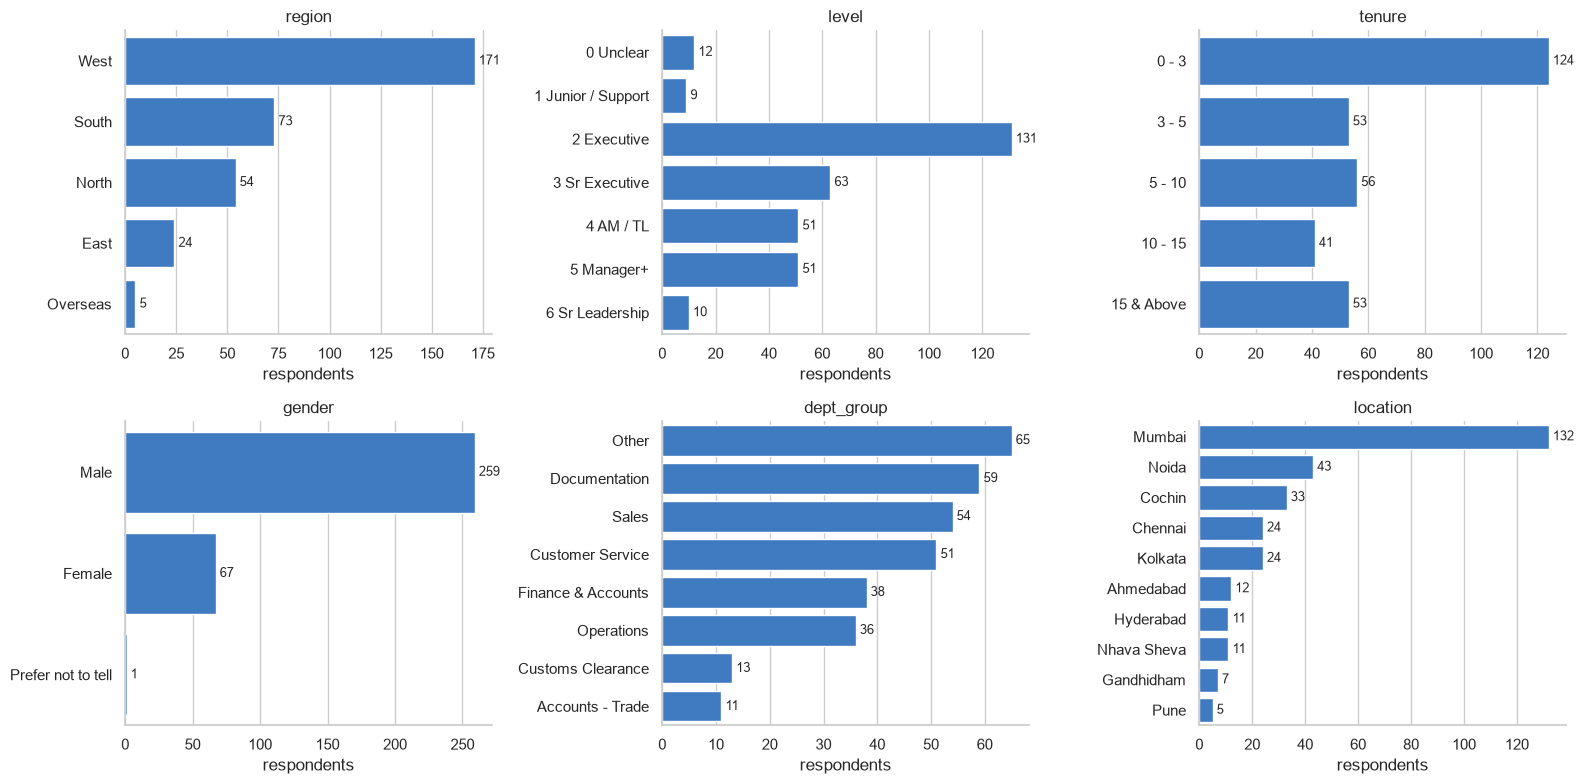

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, ["region", "level", "tenure", "gender", "dept_group", "location"]):
    vc = df[col].value_counts(sort=col not in ["tenure", "level"]).sort_index() if col in ["tenure", "level"] \
        else df[col].value_counts().head(10)
    sns.barplot(x=vc.values, y=vc.index.astype(str), ax=ax, color=BLUE)
    ax.bar_label(ax.containers[0], padding=3, fontsize=9)
    ax.set(title=col, xlabel="respondents", ylabel="")
plt.tight_layout()

Mumbai and shorter-tenure employees form large shares of the respondent pool. These are **respondent composition**, not workforce composition: eligible employee counts were not provided. Always show group sizes. For presentation, use a provisional minimum group size of 10 and review possible identification; this is a project reporting rule, not a guarantee of anonymity or statistical adequacy.

## 6. Likert items

In [23]:
dist = (df[ITEMS].apply(lambda c: c.value_counts(normalize=True)).T.reindex(columns=[1, 2, 3, 4, 5]).fillna(0) * 100)
dist.index = [f"{c}  {q[:60]}" for c, q in zip(ITEMS, codebook.set_index("col").loc[ITEMS, "question"])]
dist = dist.iloc[::-1]

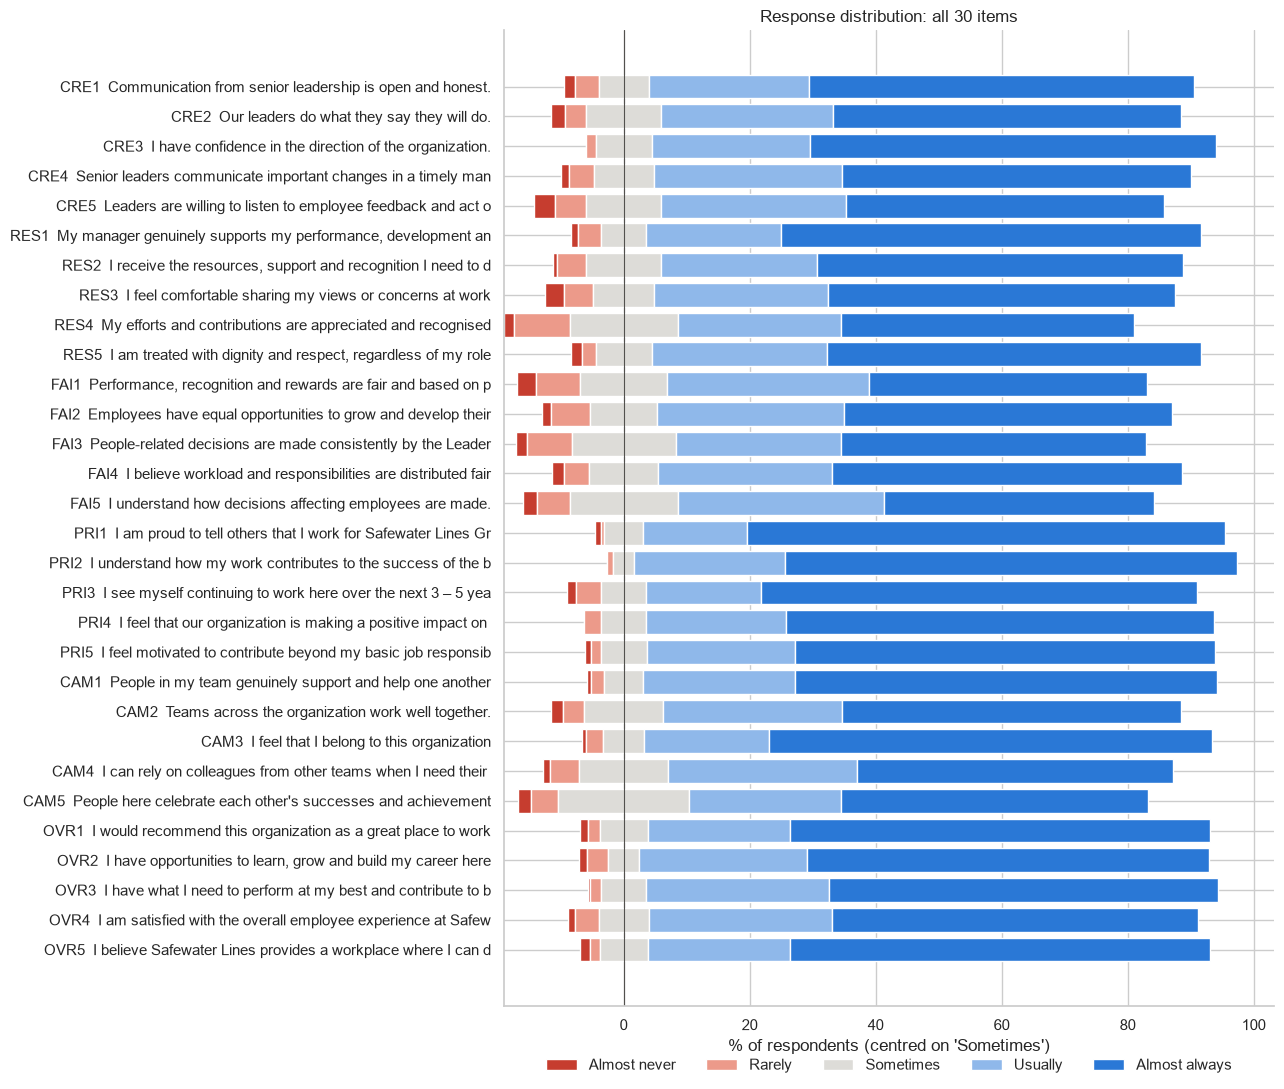

In [24]:
fig, ax = plt.subplots(figsize=(13, 11))
left = -(dist[1] + dist[2] + dist[3] / 2)
for k, color in zip([1, 2, 3, 4, 5], LIKERT_COLORS):
    ax.barh(dist.index, dist[k], left=left, color=color, edgecolor="white", linewidth=1,
            label=["Almost never", "Rarely", "Sometimes", "Usually", "Almost always"][k - 1])
    left = left + dist[k]
ax.axvline(0, color="#52514e", lw=0.8)
ax.set(xlabel="% of respondents (centred on 'Sometimes')", title="Response distribution: all 30 items")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.04), frameon=False)
plt.tight_layout()

In [25]:
# Keep full precision for calculations and sorting; round only for display.
item_counts = pd.DataFrame({k: df[ITEMS].eq(k).sum() for k in range(1, 6)})
valid_n = df[ITEMS].count()
item_stats = pd.DataFrame({
    "valid_n": valid_n,
    "missing_n": len(df) - valid_n,
    "mean": df[ITEMS].mean(),
    "median": df[ITEMS].median(),
    "favourable_n": item_counts[[4, 5]].sum(axis=1),
    "fav_%": item_counts[[4, 5]].sum(axis=1).div(valid_n).mul(100),
    "sometimes_%": item_counts[3].div(valid_n).mul(100),
    "unfav_%": item_counts[[1, 2]].sum(axis=1).div(valid_n).mul(100),
    "top_box_%": item_counts[5].div(valid_n).mul(100),
})
display(item_stats.assign(question=codebook.set_index("col")["question"])
        .sort_values("mean").round(2))

,valid_n,missing_n,mean,median,favourable_n,fav_%,sometimes_%,unfav_%,top_box_%,question
RES4,327,0,4.07,4.0,237,72.48,17.13,10.40,46.48,My efforts and contributions are appreciated and recognised
FAI1,327,0,4.07,4.0,249,76.15,13.76,10.09,44.04,"Performance, recognition and rewards are fair and based on performance."
FAI5,327,0,4.09,4.0,247,75.54,17.13,7.34,42.81,I understand how decisions affecting employees are made.
FAI3,327,0,4.12,4.0,244,74.62,16.51,8.87,48.32,People-related decisions are made consistently by the Leadership team withou...
CAM5,327,0,4.13,4.0,238,72.78,20.80,6.42,48.62,People here celebrate each other's successes and achievements.
CRE5,327,0,4.19,5.0,261,79.82,11.93,8.26,50.46,Leaders are willing to listen to employee feedback and act on it.
CAM4,327,0,4.23,5.0,262,80.12,14.07,5.81,50.15,I can rely on colleagues from other teams when I need their support.
FAI2,327,0,4.24,5.0,267,81.65,10.70,7.65,51.99,Employees have equal opportunities to grow and develop their careers.
RES3,327,0,4.27,5.0,270,82.57,9.79,7.65,55.05,I feel comfortable sharing my views or concerns at work
CAM2,327,0,4.29,5.0,269,82.26,12.54,5.20,53.82,Teams across the organization work well together.


Many responses occupy the highest categories. Show both absolute distributions and relative differences: a high average can coexist with employees reporting negative experiences. Small ranking changes need not be meaningful organisational differences.

## 7. Dimensions & reliability

In [26]:
def cronbach_alpha(x: pd.DataFrame) -> float:
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

rel = pd.DataFrame({
    "mean": [df[d].mean() for d in DIMS],
    "fav_%": [(df[[f"{d}{i}" for i in range(1, 6)]] >= 4).mean().mean() * 100 for d in DIMS],
    "alpha": [cronbach_alpha(df[[f"{d}{i}" for i in range(1, 6)]]) for d in DIMS],
}, index=DIMS).round(2)
rel.sort_values("mean")

,mean,fav_%,alpha
FAI,4.17,78.23,0.86
RES,4.32,82.63,0.88
CRE,4.35,84.77,0.88
CAM,4.35,83.30,0.79
OVR,4.48,89.42,0.90
PRI,4.58,91.19,0.84


Cronbach's alpha describes internal consistency for the proposed blocks under its assumptions. It does not establish a single underlying factor, construct validity, or independence of dimensions. A high overall alpha is a reason to inspect overlap; it does not prove a halo effect. These summaries remain descriptive rather than validated latent measures.

In [27]:
alpha_all = cronbach_alpha(df[ITEMS])
alpha_all

np.float64(0.9664818681466951)

In [28]:
def item_total(d):
    sub = df[[f"{d}{i}" for i in range(1, 6)]]
    return sub.apply(lambda c: c.corr(sub.drop(columns=c.name).sum(axis=1)))

pd.concat([item_total(d) for d in DIMS]).round(2).sort_values().head(8)

CAM3    0.51
CAM1    0.53
CAM4    0.59
CAM2    0.60
PRI2    0.61
PRI1    0.62
PRI4    0.63
FAI5    0.63
dtype: float64

Corrected item–total correlations compare each item with the remaining items in its block. Lower values prompt a wording or construct review; they are not an automatic reason to remove an item or proof that it carries a separate useful signal.

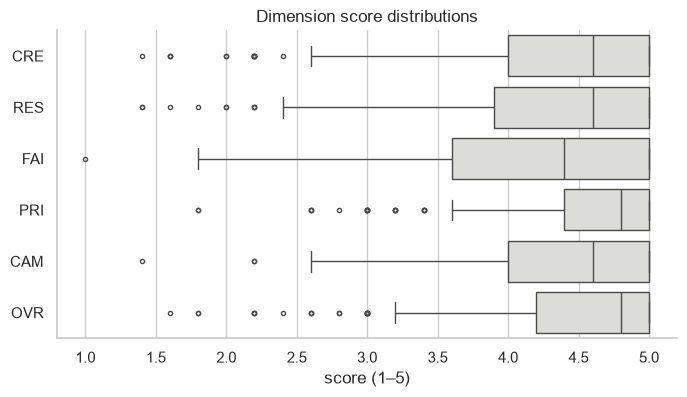

In [29]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df[DIMS], orient="h", color="#dddcd8", fliersize=3, ax=ax)
ax.set(xlabel="score (1–5)", title="Dimension score distributions");

## 8. Correlations

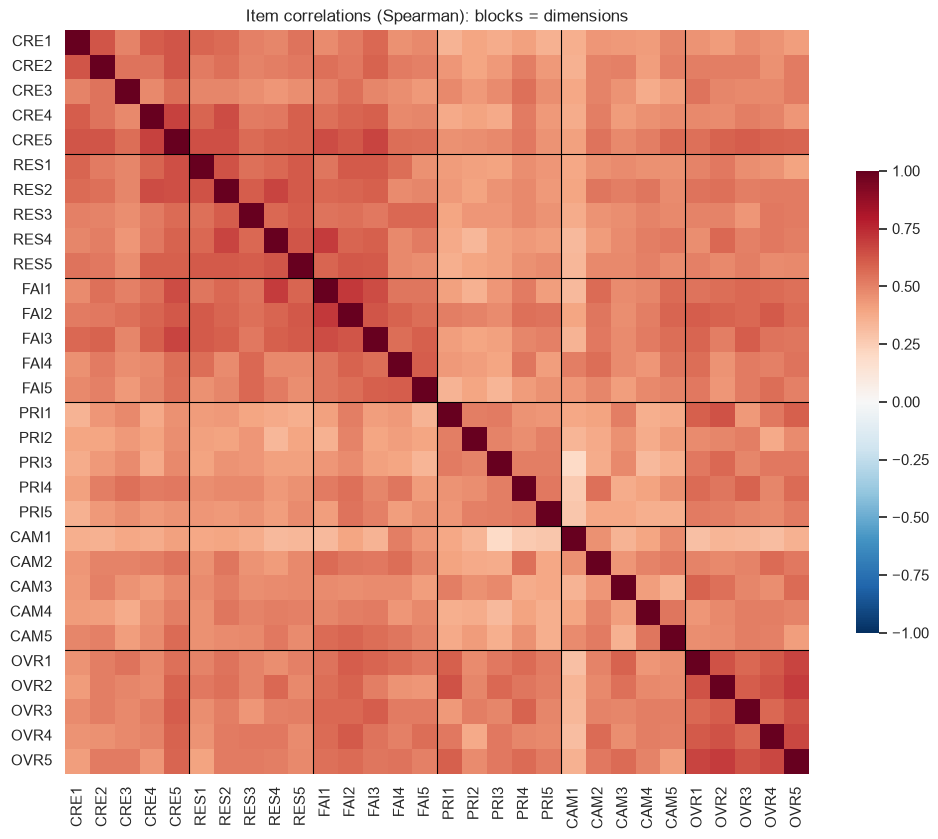

In [30]:
item_corr = df[ITEMS].corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(item_corr, cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax, cbar_kws={"shrink": 0.6})
for b in range(5, 30, 5):
    ax.axhline(b, color="black", lw=0.8); ax.axvline(b, color="black", lw=0.8)
ax.set_title("Item correlations (Spearman): blocks = dimensions");

In [31]:
within = np.mean([item_corr.loc[[f"{d}{i}" for i in range(1, 6)], [f"{d}{i}" for i in range(1, 6)]]
                  .values[np.triu_indices(5, 1)].mean() for d in DIMS])
overall = item_corr.values[np.triu_indices(30, 1)].mean()
round(within, 2), round(overall, 2)

(np.float64(0.56), np.float64(0.49))

Within-block and across-item correlations suggest overlap worth investigating. These averages cannot establish how many factors exist. EFA/CFA is conditional on a measurement question that matters to our conclusions, appropriate treatment of ordinal data, and an adequate validation plan; it is not a required next step.

### Exploratory associations with directly measured outcome items

`OVR1` measures recommendation/advocacy on this survey's 1–5 scale; it is **not eNPS**. `PRI3` measures intention to stay for 3–5 years, not actual retention. `OVR4` measures overall satisfaction. Analyse them separately rather than inventing one engagement outcome. Predictors below exclude all three outcome items.

In [32]:
OUTCOMES = {"OVR1": "recommend", "PRI3": "stay 3–5 yrs", "OVR4": "satisfied"}
drivers = [c for c in ITEMS if c not in OUTCOMES]
out_corr = df[drivers + list(OUTCOMES)].corr(method="spearman").loc[drivers, list(OUTCOMES)]
out_corr.columns = OUTCOMES.values()
out_corr.assign(q=codebook.set_index("col").loc[drivers, "question"].str[:60]).sort_values("stay 3–5 yrs", ascending=False).head(10).round(2)

,recommend,stay 3–5 yrs,satisfied,q
OVR2,0.64,0.57,0.64,"I have opportunities to learn, grow and build my career here"
OVR5,0.68,0.53,0.67,I believe Safewater Lines provides a workplace where I can d
PRI1,0.60,0.52,0.53,I am proud to tell others that I work for Safewater Lines Gr
PRI5,0.52,0.51,0.48,I feel motivated to contribute beyond my basic job responsib
PRI4,0.57,0.51,0.49,I feel that our organization is making a positive impact on
PRI2,0.47,0.50,0.38,I understand how my work contributes to the success of the b
OVR3,0.58,0.49,0.57,I have what I need to perform at my best and contribute to b
CRE5,0.55,0.48,0.59,Leaders are willing to listen to employee feedback and act o
CAM3,0.59,0.48,0.46,I feel that I belong to this organization
FAI2,0.61,0.47,0.62,Employees have equal opportunities to grow and develop their


These are bivariate Spearman associations for exploration, not causal drivers or independent effects. Shared questionnaire context, correlated items, and response styles may influence them. No claim about inflation is established here. Use the pattern and robustness checks to guide further questions; regression is conditional, not automatically required.

## 9. Exploratory segment comparisons

Show group size, mean/median culture summary, and the separate 30-item favourable percentage. Exclude groups below 10 from testing and suppress their scores in the displayed table. The rule is provisional. Approximate rank tests assume independent respondent records; group distributions may differ in shape, so a result is not automatically a median difference. No workforce generalisation is established.

The combined test table below applies **Benjamini–Yekutieli FDR adjustment across all 11 listed exploratory tests**: six full-sample comparisons and five response-style sensitivity comparisons. We use this dependency-tolerant option because the tests overlap. Adjusted p-values do not measure business importance or repair nonresponse bias. See [SciPy FDR documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.false_discovery_control.html) and [Kruskal documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.kruskal.html).

In [33]:
MIN_GROUP_N = 10  # provisional reporting rule, not a universal standard

def seg(col, data=None, score="CULTURE_MEAN"):
    data = df if data is None else data
    g = data.groupby(col, observed=True)
    t = g[score].agg(n="size", mean="mean", median="median")
    t["all_30_fav_pct"] = g["fav_pct"].mean()
    t["small_n"] = t["n"] < MIN_GROUP_N
    t.loc[t["small_n"], ["mean", "median", "all_30_fav_pct"]] = np.nan
    groups = [x[score].dropna().to_numpy() for _, x in g if len(x) >= MIN_GROUP_N]
    p = stats.kruskal(*groups).pvalue if len(groups) > 1 else np.nan
    return t.round(2), p

In [34]:
seg("tenure")[0]

,n,mean,median,all_30_fav_pct,small_n
tenure,,,,,
0 - 3,124,4.30,4.40,83.20,False
3 - 5,53,4.21,4.36,81.45,False
5 - 10,56,4.38,4.54,84.88,False
10 - 15,41,4.70,4.88,95.53,False
15 & Above,53,4.32,4.48,84.28,False


In [35]:
seg("level")[0]

,n,mean,median,all_30_fav_pct,small_n
level,,,,,
0 Unclear,12,4.20,4.16,84.44,False
1 Junior / Support,9,NaN,NaN,NaN,True
2 Executive,131,4.40,4.64,86.01,False
3 Sr Executive,63,4.22,4.28,80.85,False
4 AM / TL,51,4.26,4.28,81.44,False
5 Manager+,51,4.44,4.68,88.24,False
6 Sr Leadership,10,4.49,4.52,90.33,False


In [36]:
seg("region")[0]

,n,mean,median,all_30_fav_pct,small_n
region,,,,,
East,24,4.35,4.46,88.47,False
North,54,4.49,4.72,87.47,False
Overseas,5,NaN,NaN,NaN,True
South,73,4.50,4.68,90.68,False
West,171,4.26,4.40,81.44,False


In [37]:
seg("dept_group")[0]

,n,mean,median,all_30_fav_pct,small_n
dept_group,,,,,
Accounts - Trade,11,4.33,4.32,86.06,False
Customer Service,51,4.09,4.28,75.75,False
Customs Clearance,13,4.45,4.64,88.72,False
Documentation,59,4.41,4.64,85.76,False
Finance & Accounts,38,4.50,4.66,91.05,False
Operations,36,4.61,4.88,93.33,False
Other,65,4.31,4.36,82.72,False
Sales,54,4.31,4.54,84.26,False


In [38]:
seg("gender")[0]

,n,mean,median,all_30_fav_pct,small_n
gender,,,,,
Female,67,4.25,4.32,81.19,False
Male,259,4.39,4.56,86.14,False
Prefer not to tell,1,NaN,NaN,NaN,True


Name supplied versus not supplied is a response-context check, not an identified bias mechanism. The groups may differ in tenure, role or other characteristics. A score difference cannot establish that disclosure caused more positive answers. Never use this variable to identify individuals in a presentation.

In [39]:
test_rows = []
for sample, data, columns in [
    ("all responses", df, ["tenure", "level", "region", "dept_group", "gender", "gave_name"]),
    ("without straight-liners (sensitivity)", df.loc[~df["straightliner"]],
     ["tenure", "level", "region", "dept_group", "gender"]),
]:
    for col in columns:
        table, p = seg(col, data)
        test_rows.append({"sample": sample, "comparison": col,
                          "groups_tested": int((~table["small_n"]).sum()),
                          "respondents_tested": int(table.loc[~table["small_n"], "n"].sum()),
                          "p_unadjusted": p})
segment_tests = pd.DataFrame(test_rows)
segment_tests["p_BY_all_11"] = np.nan
eligible = segment_tests["p_unadjusted"].notna()
segment_tests.loc[eligible, "p_BY_all_11"] = stats.false_discovery_control(
    segment_tests.loc[eligible, "p_unadjusted"], method="by")
display(segment_tests.round(4))

,sample,comparison,groups_tested,respondents_tested,p_unadjusted,p_BY_all_11
0,all responses,tenure,5,327,0.0012,0.0279
1,all responses,level,6,318,0.2375,0.7172
2,all responses,region,4,322,0.0378,0.2509
3,all responses,dept_group,8,327,0.0113,0.0939
4,all responses,gender,2,326,0.0837,0.3475
5,all responses,gave_name,2,327,0.0053,0.0583
6,without straight-liners (sensitivity),tenure,5,273,0.0017,0.0279
7,without straight-liners (sensitivity),level,5,258,0.0613,0.2910
8,without straight-liners (sensitivity),region,4,268,0.0516,0.2858
9,without straight-liners (sensitivity),dept_group,8,273,0.1460,0.4849


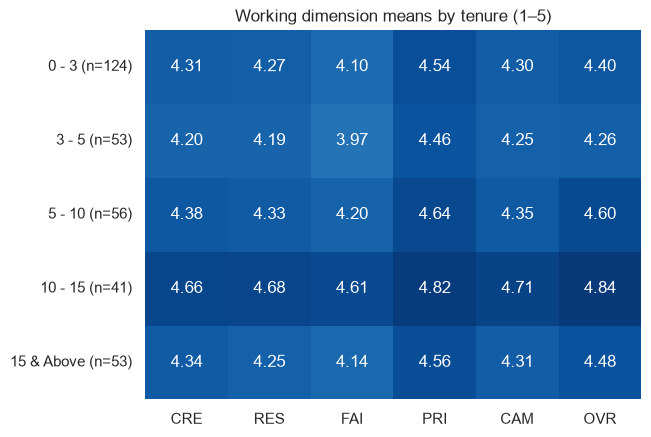

In [40]:
seg_dim = df.groupby("tenure", observed=True)[DIMS].mean()
tenure_n = df.groupby("tenure", observed=True).size().reindex(seg_dim.index)
seg_dim.loc[tenure_n < MIN_GROUP_N] = np.nan
seg_dim.index = [f"{label} (n={n})" for label, n in zip(seg_dim.index, tenure_n)]
sns.heatmap(seg_dim, annot=True, fmt=".2f", cmap="Blues", cbar=False, vmin=1, vmax=5)
plt.title("Working dimension means by tenure (1–5)");

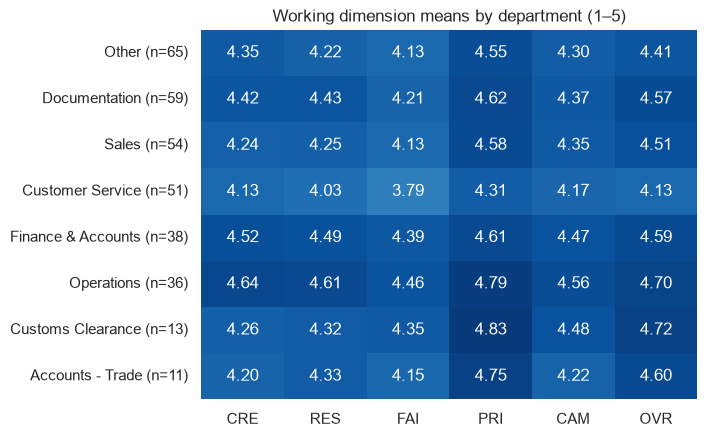

In [41]:
seg_dim = df.groupby("dept_group", observed=True)[DIMS].mean()
dept_n = df.groupby("dept_group", observed=True).size()
seg_dim = seg_dim.loc[dept_n.sort_values(ascending=False).index]
dept_n = dept_n.reindex(seg_dim.index)
seg_dim.loc[dept_n < MIN_GROUP_N] = np.nan
seg_dim.index = [f"{label} (n={n})" for label, n in zip(seg_dim.index, dept_n)]
sns.heatmap(seg_dim, annot=True, fmt=".2f", cmap="Blues", cbar=False, vmin=1, vmax=5)
plt.title("Working dimension means by department (1–5)");

### Sensitivity: compare with and without straight-liners

The full sample remains the main analysis. Exclusion changes the sample and is not a correction toward a known truth. Inspect changes in size and ranking, not merely whether a p-value crosses a threshold.

In [42]:
pd.DataFrame({
    "all": df[DIMS].mean(),
    "no_straightliners": df.loc[~df["straightliner"], DIMS].mean(),
}).assign(diff=lambda t: t["no_straightliners"] - t["all"]).round(2)

,all,no_straightliners,diff
CRE,4.35,4.24,-0.11
RES,4.32,4.20,-0.12
FAI,4.17,4.02,-0.15
PRI,4.58,4.51,-0.07
CAM,4.35,4.24,-0.11
OVR,4.48,4.39,-0.09


## 10. HR priority (single choice)

In [43]:
theme = pd.read_excel(xl, "Sheet2", header=2).iloc[:10, [0, 2]].set_axis(["option", "theme"], axis=1)
theme["theme"] = theme["theme"].str.strip()
df["hr_theme"] = df["hr_priority"].map(dict(zip(theme["option"], theme["theme"])))
df["hr_theme"].isna().sum()

np.int64(0)

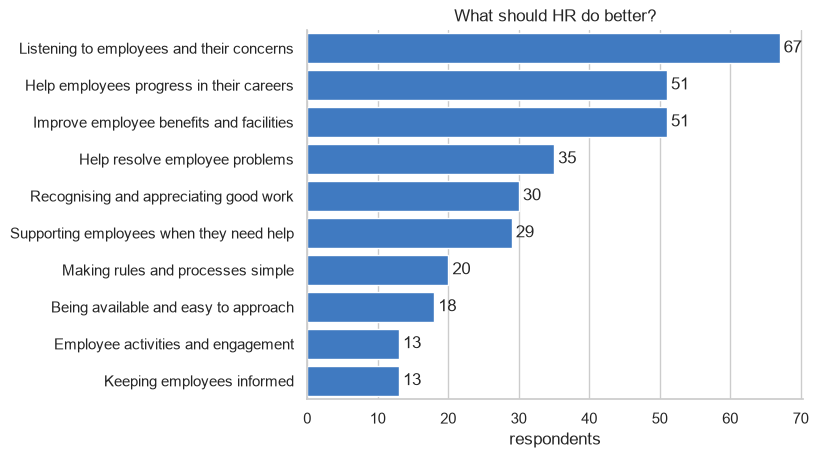

In [44]:
hr = df["hr_priority"].value_counts()
ax = sns.barplot(x=hr.values, y=hr.index, color=BLUE)
ax.bar_label(ax.containers[0], padding=3)
ax.set(title="What should HR do better?", xlabel="respondents", ylabel="");

In [45]:
df["hr_theme"].value_counts(normalize=True).round(3) * 100

hr_theme
Communication            24.5
Grievances               19.6
Development              15.6
Benefits & Facilities    15.6
R&R                       9.2
Process & Policies        6.1
Approachable              5.5
Engagement                4.0
Name: proportion, dtype: float64

In [46]:
def hr_association(col):
    # Descriptive Cramér's V; inspect expected counts before offering an asymptotic p-value.
    counts = df[col].value_counts()
    included = counts[counts >= MIN_GROUP_N].index
    subset = df.loc[df[col].isin(included)]
    ct = pd.crosstab(subset[col], subset["hr_theme"])
    result = stats.chi2_contingency(ct, correction=False)
    denom = ct.to_numpy().sum() * (min(ct.shape) - 1)
    sparse = bool((result.expected_freq < 5).any())
    return {"n_included": len(subset),
            "descriptive_V": np.sqrt(result.statistic / denom) if denom else np.nan,
            "minimum_expected": result.expected_freq.min(),
            "expected_cells_below_5_pct": (result.expected_freq < 5).mean() * 100,
            "asymptotic_p": result.pvalue if not sparse else np.nan,
            "status": "withheld: sparse expected counts" if sparse else "exploratory only"}

hr_associations = pd.DataFrame({c: hr_association(c)
    for c in ["tenure", "level", "region", "dept_group", "gender"]}).T
display(hr_associations)

,n_included,descriptive_V,minimum_expected,expected_cells_below_5_pct,asymptotic_p,status
tenure,327,0.154651,1.629969,40.0,NaN,withheld: sparse expected counts
level,318,0.137937,0.377358,58.333333,NaN,withheld: sparse expected counts
region,322,0.171939,0.968944,40.625,NaN,withheld: sparse expected counts
dept_group,327,0.188263,0.437309,59.375,NaN,withheld: sparse expected counts
gender,326,0.162074,2.671779,18.75,NaN,withheld: sparse expected counts


The single-choice HR question shows the **one selected priority**, not every need an employee has. Cramér's V above is descriptive and can be unstable in sparse tables; no p-values are reported where any expected count is below five. Do not claim a department effect from the original unchecked chi-square calculation. If a decision requires inference, consider a justified permutation approach later. See [SciPy contingency-table guidance](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html).

## 11. Open-ended answers: coverage before interpretation

Profile missing and short responses without equating brevity with uselessness. A response such as *nothing* can mean no concern when asked about fairness; *good* may express approval. Flag ambiguous placeholders for contextual review rather than deleting them automatically. No raw comments are displayed here.

In [47]:
txt = df[OE].astype("string").apply(lambda c: c.str.strip().replace("", pd.NA))
PLACEHOLDER = r"^(?:nil|na|n/a|no|none|nothing|ok|okay|yes|good|-|\.|no comments?|nothing to say|all good|no suggestions?)\.?$"
profile = pd.DataFrame({
    "nonblank_n": txt.notna().sum(),
    "blank_%": txt.isna().mean() * 100,
    "context_review_%": txt.apply(
        lambda c: c.str.lower().str.fullmatch(PLACEHOLDER).fillna(False)).mean() * 100,
    "median_words_nonblank": txt.apply(lambda c: c.str.split().str.len()).median(),
})
display(profile.round(1))

,nonblank_n,blank_%,context_review_%,median_words_nonblank
oe_leaders_trust,318,2.8,5.2,8.0
oe_feel_valued,316,3.4,5.5,8.0
oe_fairness_concern,308,5.8,10.1,7.0
oe_value_most,318,2.8,4.6,6.0
oe_teamwork,317,3.1,4.6,7.0
oe_one_change,315,3.7,6.4,8.0


Repeated wording is a review flag, not evidence of machine-generated or dishonest answers. Repeated short answers may be legitimate. Later coding should preserve context, allow multiple codes, document ambiguous cases, and redact identifying details from any presentation excerpts.

In [48]:
pd.DataFrame({
    "nonblank_n": txt.notna().sum(),
    "rows_in_repeated_text_groups": txt.apply(
        lambda c: (c.str.casefold().duplicated(keep=False) & c.notna()).sum()),
})

,nonblank_n,rows_in_repeated_text_groups
oe_leaders_trust,318,33
oe_feel_valued,316,38
oe_fairness_concern,308,47
oe_value_most,318,47
oe_teamwork,317,29
oe_one_change,315,24


## 12. Save processed data

In [49]:
OUT.mkdir(parents=True, exist_ok=True)
df.to_csv(OUT / "survey_clean.csv", index=False)
codebook.to_csv(OUT / "codebook.csv", index=False)
df.shape

(327, 56)

## Summary: exploratory baseline, not the final organisational story

- **327 master responses**, 30 rating items in six supplied blocks, six comment questions and one HR-priority choice. Five demographic fields are retained; the optional name is removed. Workforce response rate is unknown.
- Ratings are mostly positive. Fairness is the lowest-scoring supplied block and Pride the highest; this is an internal comparison, not an external benchmark or certification.
- 54 respondents give the same rating throughout. About 69% supply a name. These are response-context observations; neither proves invalid answers, a halo effect, or the magnitude/direction of bias.
- Existing associations suggest questions about growth, intention to stay, recognition and communication. They do not establish what causes actual retention or engagement.
- Segment patterns are exploratory. Review group sizes and adjusted comparisons before making subgroup claims. Sparse HR-priority tables do not support the previous unchecked chi-square p-values.
- At this EDA stage comments are profiled only; **Step 3 below now contains an exploratory semantic coding pass**. Selected HR priorities are not equivalent to comment themes.

**Next: Step 1 below establishes the questions, measures and method choices.** Further analysis will combine item distributions, defensible comparisons and contextual comment coding. Recommendations and the PowerPoint follow the completed evidence review.

# Step 1 — Analytical foundation and method choices

**Status:** foundation and research are recorded here. Steps 2–4 below now add descriptive follow-up, single-assistant contextual comment coding, n-grams and an integrated evidence/action-options register. Final team validation, priority selection and PowerPoint remain later stages. All analysis will stay in this notebook.

Our working philosophy is **decision first, evidence before explanation, and employee voice with follow-through**. Preserve strengths as well as address gaps. Prefer the simplest analysis that answers the decision, and state what it cannot establish. CIPD describes people analytics as solving organisational problems with people data and combining it with expertise, research and stakeholder perspectives. [CIPD guide](https://www.cipd.org/uk/knowledge/guides/analytics-practitioner-guide/).

The survey records one-time perceptions. Population size, response rate, workforce composition, survey administration details, earlier results and linked turnover/performance outcomes were not supplied. Describe respondents, use hypotheses for explanations, and make no causal or financial-return claims from these data alone.

## 1.1 What decisions must the analysis support?

These mappings follow question wording; they are **not newly validated scales**. The HR-priority item is separate from comment themes.

| Organisation question | Survey evidence | First analysis | Decision it may inform |
|---|---|---|---|
| What should we preserve? | All 30 item distributions, especially PRI and CAM; `oe_value_most` | Identify consistently positive experiences and read comments for what employees value | Practices to protect while changing other processes |
| Where is leadership trust vulnerable? | CRE1–5; `oe_leaders_trust`; communication-related HR choices | Item distributions and coded accounts of communication, promises and follow-through | Leadership listening and communication practices |
| Where do employees feel insufficiently valued or supported? | RES1–5, OVR3; `oe_feel_valued` | Separate support, resources, recognition and respectful treatment | Manager support, resource provision and recognition |
| Which aspects of fairness need attention? | FAI1–5, relevant comments | Separate rewards, opportunities, decision consistency, workload and explanations | Clarify which policy or decision process to review |
| Where could growth or experience improve? | OVR2, OVR4–5; PRI3; `oe_one_change` | Direct outcomes and exploratory associations, excluding the outcome from its predictors | Career conversations and experience improvements; not individual attrition prediction |
| How well do teams work together? | CAM1–5; `oe_teamwork` | Separate within-team support from cross-team collaboration | Collaboration and handover practices |
| Whose experience differs? | Tenure, department, region, gender; approximate role groups | Group sizes, distributions and differences, with response-style sensitivity | Targeted follow-up after checking context and possible confounding |
| What should HR do first? | Single-choice `hr_priority`, coded comments, rating gaps | Triangulate employee-selected priorities with recurring concerns and relative strengths | A short, justified intervention list with proposed owners and success measures |

## 1.2 Establish the base before interpreting scores

The table below verifies the analytical unit and coverage using the actual in-memory data. An employee record is the unit for respondent comparisons. Item responses are the unit for pooled answer percentages; 30 answers from one employee are not 30 independent employees.

In [50]:
assert len(ITEMS) == 30 and len(set(ITEMS)) == 30
assert len(raw) == len(df) and raw.index.equals(df.index)
assert df[ITEMS].isin([1, 2, 3, 4, 5]).all().all(), "Review missing/unmapped ratings"
assert "full_name" not in df.columns
assert item_counts.sum(axis=1).eq(valid_n).all()
assert np.allclose(item_stats[["fav_%", "sometimes_%", "unfav_%"]].sum(axis=1), 100)
assert df["hr_theme"].notna().all(), "Review unmapped HR-priority options"

base_register = pd.DataFrame([
    ("Unit of analysis", "One master response record; unique employee identity is not verified"),
    ("Master response records", len(df)),
    ("Rating items / supplied blocks", f"{len(ITEMS)} / {len(DIMS)}"),
    ("Valid rating answers", int(valid_n.sum())),
    ("Valid answers per rating item", f"{int(valid_n.min())}–{int(valid_n.max())}"),
    ("Missing rating answers", int(df[ITEMS].isna().sum().sum())),
    ("Identical-category response records", int(df["straightliner"].sum())),
    ("Nonblank answers across six comment questions", int(txt.notna().sum().sum())),
    ("Comment contributors (at least one nonblank answer)", int(txt.notna().any(axis=1).sum())),
    ("Valid single-choice HR-priority records", int(df["hr_priority"].notna().sum())),
    ("Eligible workforce / response rate", "Not provided / not calculable"),
    ("External benchmark / previous wave", "Not provided / not provided"),
], columns=["Base parameter", "Observed value or limitation"])
display(base_register)

,Base parameter,Observed value or limitation
0,Unit of analysis,One master response record; unique employee identity is not verified
1,Master response records,327
2,Rating items / supplied blocks,30 / 6
3,Valid rating answers,9810
4,Valid answers per rating item,327–327
5,Missing rating answers,0
6,Identical-category response records,54
7,Nonblank answers across six comment questions,1892
8,Comment contributors (at least one nonblank answer),321
9,Valid single-choice HR-priority records,327


## 1.3 Measurement contract

| Measure | Definition / denominator | Interpretation rule |
|---|---|---|
| Item response distribution | Count in each of 1–5 divided by valid responses to that item | Primary evidence; category 3 is Sometimes, not neutral |
| Favourable % | Count of 4–5 / valid item responses ×100 | Convenient summary; always retain lower categories and top-box |
| Unfavourable % / top-box % | Count of 1–2 / valid n; count of 5 / valid n | Distinguish reported problems from intensity of positive answers |
| Working item/block mean | Equal-spaced 1–5 coding; block is an equal-weight five-item mean | Transparent approximation, not proof of interval measurement or a validated construct |
| Culture summary | Equal-weight 25-item mean, excluding OVR | Optional descriptive overview; avoid part–whole outcome correlations |
| Advocacy / intention to stay / satisfaction | OVR1 / PRI3 / OVR4, each kept separate | Direct survey perceptions, not eNPS, actual turnover or observed performance |
| Segment difference | Show group n and differences on the same measure | Report percentage points for percentage differences; no unsupported population extrapolation |
| Selected HR priority | Option count / valid answers to the single-choice item | One selected priority, not prevalence of every concern |
| Comment-topic mentions — used in Step 3 | Unique contributors mentioning topic / explicitly stated contributor base | Multi-label totals can exceed 100%; count people once per topic across questions if using a person-level base |
| Response-style sensitivity | Full-sample result versus a clearly labelled alternative sample | Excluding straight-liners is not assumed to recover the truth |

Our display convention follows the practical use of distributions and positive-response shares in employee surveys, while keeping the full scale visible. The Civil Service methodology illustrates why a mean-based index and a favourable percentage carry different information; its questionnaire, index and benchmarks are **not transferred** to Safewater Lines. [Civil Service methodology](https://www.gov.uk/government/publications/civil-service-people-survey-2025-results/quality-and-methodology-information-for-the-civil-service-people-survey-2025).

## 1.4 Research: what fits this project?

Sources consulted 28 October 2026. The decisions below are our assessment of fit, not endorsements of this dataset by the authors.

| Source / perspective | Useful lesson | Our decision |
|---|---|---|
| [CIPD: people analytics](https://www.cipd.org/uk/knowledge/guides/analytics-practitioner-guide/) | Connect the investigation to a decision and combine several forms of evidence | Adopt a question-to-action structure; seek business context before final recommendations |
| [Civil Service survey methodology](https://www.gov.uk/government/publications/civil-service-people-survey-2025-results/quality-and-methodology-information-for-the-civil-service-people-survey-2025) | A positive-response share can hide different full-scale patterns | Adopt distributions plus favourable %, with clear denominators; do not borrow its engagement index or benchmark |
| [ASA statement](https://doi.org/10.1080/00031305.2016.1154108) | Statistical evidence needs context; a threshold does not establish importance | Report observed differences, sample context and limitations; keep tests exploratory |
| [SciPy: contingency tables](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html) | Sparse expected frequencies undermine a routine asymptotic chi-square interpretation | Audit the table before inference; current sparse-table p-values are withheld |
| [Braun & Clarke: types of thematic analysis](https://www.thematicanalysis.net/understanding-ta/) and [review guidance](https://www.thematicanalysis.net/editor-checklist/) | Codebook, coding-reliability and reflexive approaches are different methodological choices | Plan a practical codebook-based content analysis for short survey comments; do not claim reflexive TA while imposing fixed codes and inter-rater reliability |
| [r/IOPsychology practitioner discussion](https://www.reddit.com/r/IOPsychology/comments/1rj1df7/need_help_conducting_my_first_employee_survey/) | Participants emphasise clear survey purposes, understandable summaries, confidentiality and meaningful follow-up | Treat this as practical experience, not validation. Do not adopt forum claims that measurement validity is unimportant |
| [Zadeh: fuzzy sets](https://doi.org/10.1016/S0019-9958(65)90241-X) | Fuzzy membership represents degrees of belonging to a defined set | Consider only with an explicit decision meaning, calibrated membership functions and sensitivity checks |
| [Di Nardo & Simone: model-based fuzzy questionnaires](https://arxiv.org/abs/1912.09883) | A fuzzy questionnaire method can incorporate a statistical model rather than merely replace category labels | Keep as a research candidate; its different application does not validate our membership choices or prove improvement here |

**Coherent quantitative approach:** use distributions as primary evidence; working means as clearly labelled summaries; rank associations and group tests only for relevant exploratory questions. This is not a blanket claim that all parametric methods are invalid for Likert data. More complex models need a clear incremental question and checks, rather than being added for appearance.

**Coherent qualitative approach — planned:** read answers in question context → draft code definitions with inclusion/exclusion examples → pilot and revise → record each coding decision and ambiguous case → review a shared subset → count unique contributors at the chosen denominator → interpret with representative, redacted excerpts. Distinguish genuine no-concern answers from missing/unclear text. Keyword matching may assist retrieval but will not be treated as completed coding or validated sentiment.

## 1.5 Fuzzy analysis: establish the added value first

Fuzzy logic allows partial membership in a concept such as “high satisfaction”; membership is not automatically a probability, a statistical confidence level, or the employee's self-reported uncertainty. Distinguish fuzzy comprehensive evaluation (FCE), fuzzy clustering and fuzzy-set QCA: they answer different questions. We have not selected any of them solely because survey opinions are subjective. [Zadeh](https://doi.org/10.1016/S0019-9958(65)90241-X).

**A useful baseline check, derived here:** let `P[j,k]` be the observed share selecting category `k` on item `j`. In a frequency-based weighted-average evaluation, using equal item weights and category scores 1–5 gives `mean_j(P[j,:]) @ [1,2,3,4,5]`. With complete data this is exactly the pooled ordinary mean. Calling that calculation fuzzy would add no information.

The check below evaluates this specific construction on our data. It does **not** implement or reject all fuzzy methods, and the response-frequency matrix is not independently elicited fuzzy membership.

In [51]:
frequency_profiles = item_counts.div(valid_n, axis=0)
category_values = np.arange(1, 6, dtype=float)
fuzzy_baseline_rows = []
for block in DIMS:
    block_items = [f"{block}{i}" for i in range(1, 6)]
    ordinary_mean = df[block_items].to_numpy(dtype=float).mean()
    frequency_evaluation = frequency_profiles.loc[block_items].mean(axis=0).to_numpy() @ category_values
    fuzzy_baseline_rows.append((block, ordinary_mean, frequency_evaluation,
                                abs(ordinary_mean - frequency_evaluation)))
fuzzy_baseline_check = pd.DataFrame(fuzzy_baseline_rows, columns=[
    "block", "ordinary_mean", "equal_weight_frequency_evaluation", "absolute_difference"])
assert np.allclose(fuzzy_baseline_check["absolute_difference"], 0, atol=1e-12)
display(fuzzy_baseline_check.round(6))

,block,ordinary_mean,equal_weight_frequency_evaluation,absolute_difference
0,CRE,4.352294,4.352294,0.0
1,RES,4.316820,4.316820,0.0
2,FAI,4.167584,4.167584,0.0
3,PRI,4.581651,4.581651,0.0
4,CAM,4.352905,4.352905,0.0
5,OVR,4.481957,4.481957,0.0


**Decision:** do not add this equivalent frequency-weighted score to the executive findings. A substantive fuzzy extension remains **conditional**, not completed. To adopt one, specify its organisational decision, justify membership anchors/weights using theory or stakeholder elicitation, compare it with the simple baseline, and test whether conclusions change across plausible calibrations. If rankings change, explain which assumption changes them; a different ranking is not evidence of greater accuracy. We currently lack elicited memberships, decision weights and an independent validation outcome.

If later we use a fuzzy model, show its incremental value and limitations in the methodology table. Fuzzy membership alone cannot recover missing workforce data, establish causality or predict actual turnover from intention-to-stay answers. Statistical fuzzy questionnaire models exist, but their calibration and fit must be examined before transferring them here. [Di Nardo & Simone](https://arxiv.org/abs/1912.09883).

## 1.6 HR concepts that help interpret the evidence

These are interpretive lenses, not extra measured variables or diagnoses.

| Concept | Meaning for our questions | Appropriate use / limit |
|---|---|---|
| Employee experience | Employees' experiences of work, support, relationships and organisational processes | Use exact items and comments; do not reduce every experience to one average |
| Engagement, satisfaction and commitment | Related concepts with different meanings | Keep measured satisfaction, advocacy, belonging and intention to stay visible rather than calling all of them one validated engagement score. [CIPD evidence review](https://www.cipd.org/en/knowledge/evidence-reviews/evidence-engagement/) |
| Organisational justice | Fairness of outcomes, procedures, interpersonal treatment and information | A useful reading lens for FAI1/4 (outcomes), FAI3 (procedures), RES5 (treatment), FAI5 (explanations); these items are not Colquitt's validated subscales. [Colquitt, 2001](https://pubmed.ncbi.nlm.nih.gov/11419799/) |
| Psychological safety | A shared team belief about interpersonal risk-taking | RES3 is relevant to speaking up, but one item does not establish Edmondson's full construct or a team-level score. [Edmondson, 1999](https://dash.harvard.edu/entities/publication/13a7b031-0fdd-45ec-a7e0-2b80e2bc679f) |
| Employee voice and closing the loop | Asking, listening, responding and showing what happens next | Treat CRE5 and comments as evidence for follow-up; measure both whether leaders act and whether employees experience improvement |
| Perceived organisational strengths | Experiences employees rate positively and say they value | Preserve them alongside improvements; a rare serious concern still deserves contextual review |
| Evidence-based HR | Combine organisational data, research, professional expertise and stakeholder views | Use our survey as one input, not as the complete business case. [CIPD guide](https://www.cipd.org/uk/knowledge/guides/analytics-practitioner-guide/) |
| Theory of change | An explicit proposal linking action to an expected mechanism and outcome | Explain why an intervention may help, then evaluate it; this is a planning hypothesis, not an observed survey result |

Advocacy remains OVR1 on a five-point frequency scale. Standard NPS uses a zero-to-ten recommendation protocol; no mechanical rescaling makes our item standard eNPS. [Bain scoring protocol](https://www.netpromotersystem.com/about/measuring-your-net-promoter-score/).

## 1.7 Where the analysis now continues

Steps 2–4 below implement useful descriptive follow-up, contextual comment coding, n-gram support and an integrated organisational story with action options. Advanced models remain conditional. The executive PowerPoint follows team review of the evidence, final priority choices and roadmap.


# Step 2 — Which additional analyses add decision value?

Updated **29 October 2026**. We now connect ratings and employee voice to practical choices. This section extends the existing analysis in the same notebook; it does not create a second analytical pipeline.

| Candidate | Does it answer a real question here? | Decision |
|---|---|---|
| Thematic content coding | What experiences, strengths and changes do employees describe, beyond their ratings? | **Use** explicit multi-label semantic coding with question context and an audit ledger |
| Bigrams / trigrams | Which recurring phrases help us navigate the comments and check topic labels? | **Use as support**, counting people rather than word repetitions; not a substitute for interpretation |
| Calibrated fuzzy model | Is there a specific decision requiring justified degrees of membership and weights? | **Not currently justified**; Step 1's equivalent frequency score adds no information; no calibrated anchors/validation outcome supplied |
| Rating–comment integration | Do several forms of evidence support a priority, or tell different stories? | **Use**, preserving both agreements and differences without forcing a causal narrative |
| Paired item profiles | Do the same respondents rate within-team support more positively than cross-team collaboration? | **Use descriptive paired counts**, avoiding a comparison of unrelated groups |
| Tenure follow-up | Which experiences merit discussion in the tenure groups already examined? | **Use limited descriptive profiles**, sample sizes and response-style checks; no individual attrition score |
| Topic models, generic sentiment, employee clustering | Would these answer an unresolved decision better than reviewed short comments and existing groups? | **Do not add now**; short/mixed-language answers, overlapping concepts and unclear decision value make them unnecessary here |
| Causal driver models, automatic EFA/CFA | Are causal outcomes or a necessary latent-measure validation problem available? | **Do not add now**; retain descriptive constructs and exploratory associations; more complexity would not establish causality |

Thematic coding here means **applied codebook-based content analysis**, not Braun & Clarke's reflexive TA. A matrix linking cases, categories and source material supports an auditable applied analysis; it does not remove interpretation. [Gale et al., Framework Method](https://pmc.ncbi.nlm.nih.gov/articles/PMC3848812/), [Braun & Clarke's method distinctions](https://www.thematicanalysis.net/understanding-ta/).

## 2.1 Which rating gaps matter, and which strengths should remain visible?

Rank on the **stated measure**. A mean and a favourable percentage summarise different features and can produce different rankings. Here favourable percentage is the main presentation summary; show Sometimes and unfavourable counts alongside it. “Not favourable” includes Sometimes and does not mean every such employee is dissatisfied. No external benchmark or good/bad cutoff is introduced.

,question,valid_n,fav_%,sometimes_n,unfavourable_n,fav_without_straightliners_pct,sensitivity_change_pp
RES4,My efforts and contributions are appreciated and recognised,327,72.48,56,34,67.40,-5.08
CAM5,People here celebrate each other's successes and achievements.,327,72.78,68,21,67.77,-5.02
FAI3,People-related decisions are made consistently by the Leadership team withou...,327,74.62,54,29,69.96,-4.65
FAI5,I understand how decisions affecting employees are made.,327,75.54,56,24,71.06,-4.47
FAI1,"Performance, recognition and rewards are fair and based on performance.",327,76.15,45,33,71.79,-4.35
CRE5,Leaders are willing to listen to employee feedback and act on it.,327,79.82,39,27,76.19,-3.63
CAM4,I can rely on colleagues from other teams when I need their support.,327,80.12,46,19,76.56,-3.57
FAI2,Employees have equal opportunities to grow and develop their careers.,327,81.65,35,25,78.39,-3.26


,question,fav_%,top_box_%
PRI2,I understand how my work contributes to the success of the business.,95.72,71.87
PRI1,I am proud to tell others that I work for Safewater Lines Group,92.35,75.84
CAM1,People in my team genuinely support and help one another,91.13,66.97
OVR3,I have what I need to perform at my best and contribute to business success.,90.83,61.77
OVR2,"I have opportunities to learn, grow and build my career here.",90.52,63.91


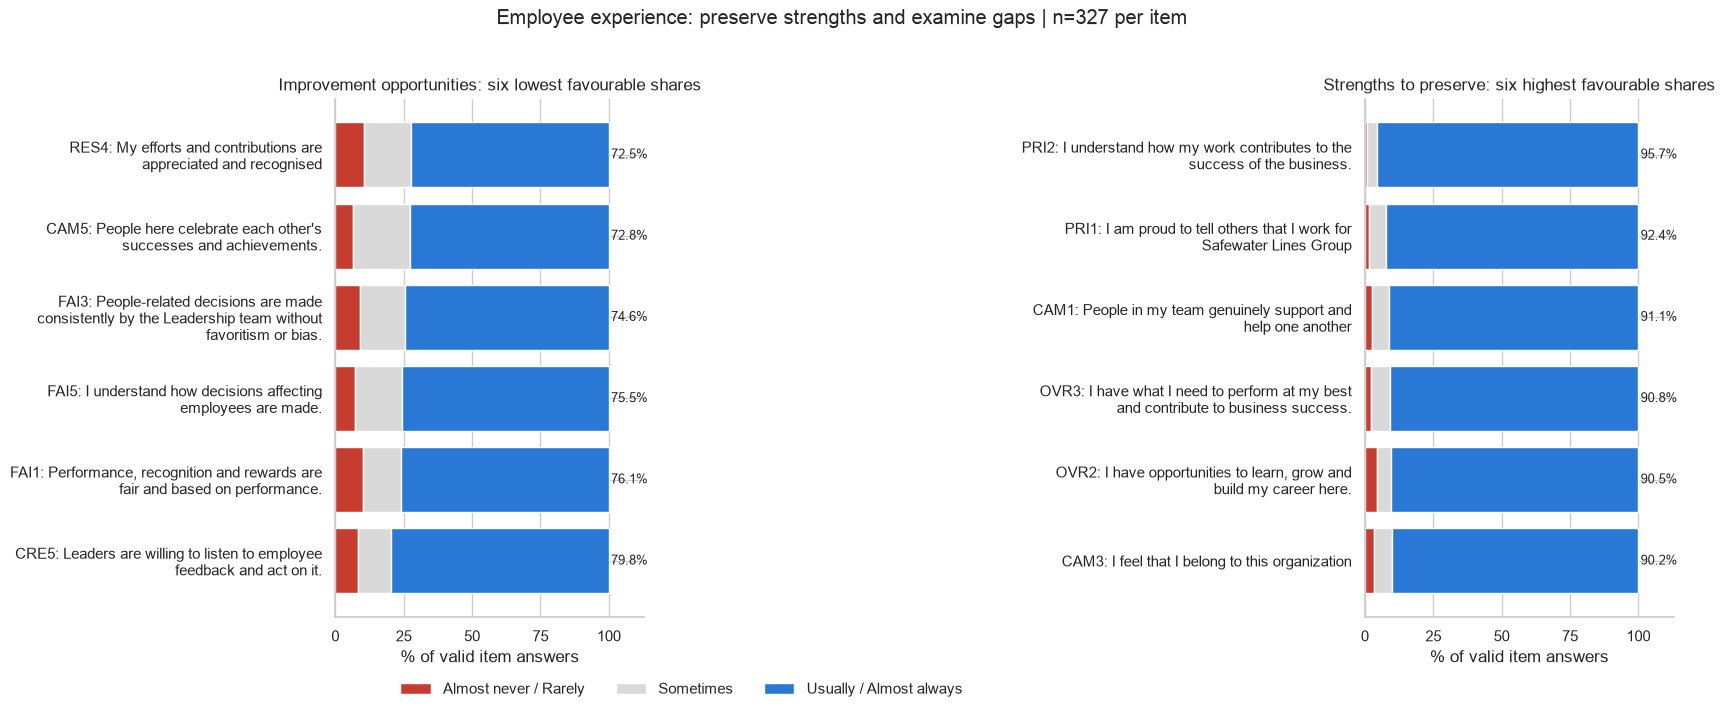

In [52]:
from collections import Counter, defaultdict
from hashlib import sha256
from textwrap import fill
import unicodedata

TABLES = ROOT / "reports/tables"
FIGURES = ROOT / "reports/figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

question_lookup = codebook.set_index("col")["question"]
rating_profile = item_stats.copy()
rating_profile["question"] = question_lookup.reindex(rating_profile.index)
rating_profile["unfavourable_n"] = item_counts[[1, 2]].sum(axis=1)
rating_profile["sometimes_n"] = item_counts[3]
rating_profile["fav_without_straightliners_pct"] = (
    df.loc[~df["straightliner"], ITEMS].ge(4).mean().mul(100))
rating_profile["sensitivity_change_pp"] = (
    rating_profile["fav_without_straightliners_pct"] - rating_profile["fav_%"])
rating_profile = rating_profile.sort_values(["fav_%", "mean"])
display(rating_profile[["question", "valid_n", "fav_%", "sometimes_n", "unfavourable_n",
                        "fav_without_straightliners_pct", "sensitivity_change_pp"]].head(8).round(2))
display(rating_profile[["question", "fav_%", "top_box_%"]].tail(5).iloc[::-1].round(2))
rating_profile.to_csv(TABLES / "item_evidence_profile.csv", index_label="item")

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, subset, title in [
    (axes[0], rating_profile.head(6), "Improvement opportunities: six lowest favourable shares"),
    (axes[1], rating_profile.tail(6).iloc[::-1], "Strengths to preserve: six highest favourable shares"),
]:
    labels = [fill(f"{item}: {row.question}", 49) for item, row in subset.iterrows()]
    left = np.zeros(len(subset))
    for key, color, label in [("unfav_%", "#c63d2f", "Almost never / Rarely"),
                               ("sometimes_%", "#d9d9d9", "Sometimes"),
                               ("fav_%", BLUE, "Usually / Almost always")]:
        ax.barh(labels, subset[key], left=left, color=color, label=label)
        left += subset[key].to_numpy()
    for y, (_, row) in enumerate(subset.iterrows()):
        ax.text(100.8, y, f"{row['fav_%']:.1f}%", va="center", fontsize=9)
    ax.invert_yaxis()
    ax.set(xlim=(0, 113), xlabel="% of valid item answers", title=title)
    ax.set_xticks([0, 25, 50, 75, 100])
axes[0].legend(loc="upper center", bbox_to_anchor=(1.12, -0.1), ncol=3, frameon=False)
fig.suptitle(f"Employee experience: preserve strengths and examine gaps | n={len(df)} per item", y=1.02)
fig.tight_layout()
fig.savefig(FIGURES / "strengths_and_opportunities.png", dpi=180, bbox_inches="tight")

# Step 3 — Employee voice: contextual thematic content analysis

## 3.1 What was actually done, and what remains uncertain?

The assistant read the six comment columns in question context, built the codebook below, assigned semantic topic labels to **every nonblank comment**, and revisited unclear entries. The coding decisions are stored explicitly in the notebook, not produced by a keyword classifier or an external API. Counts are reproducible from the ledger. The ledger uses source row positions solely for traceability; these are not verified unique employee IDs.

**This is one AI-assisted coding pass, not independently human-validated qualitative research.** A second team member has not reviewed these decisions; inter-rater reliability, coding accuracy, saturation and language equivalence have not been established. The resulting topic counts and interpretations are exploratory. Before final presentation, a team member should review the codebook, uncertain/cross-referenced answers, material supporting each priority and the serious issue descriptions. No invented agreement statistic is reported.

Rules applied:

- Code what is actually said; allow several topics. Do not label the phrase “this would help me feel supported” as a support problem unless support is substantively requested.
- Distinguish suggested improvements, current strengths, mixed accounts, no concern/change proposed, unclear responses, item nonresponses and no valued aspect identified.
- A negative answer to “where is the fairness concern?” is preserved as **no concern reported**, not removed as useless text. “Nothing” in the strengths question instead means no valued aspect identified.
- A request does not necessarily report a failure or incident. Asking for more recognition can coexist with a favourable recognition rating.
- Short comments may be meaningful. Do not discard them, speculate about who wrote them, or infer dishonesty from polished/repeated phrasing.
- Preserve specific facilities, respectful-treatment and boundary concerns in the interpretation even if they are less frequent than generic requests.
- No verbatim comments, names, named accusations or source-row IDs are exported in presentation tables. Illustration text below is explicitly **paraphrase**, not quotation.

The initial topic framework follows the brief, with additions grounded in the comments (for example facilities, role clarity and pay). Broad topics summarise content; they are not validated psychological constructs. Framework organisation and codebook analysis are distinct from reflexive TA. [Gale et al.](https://pmc.ncbi.nlm.nih.gov/articles/PMC3848812/), [Braun & Clarke's reporting guidance](https://www.thematicanalysis.net/editor-checklist/).

In [53]:
# Topic definitions include inclusion and exclusion rules; examples are analyst paraphrases.
TOPIC_DEFINITIONS = {
    "c": ("Communication and decision explanations", "Updates, transparency, information sharing or reasons for decisions", "Not every use of the word clear; role clarity belongs to p", "Explain decisions and keep people informed"),
    "v": ("Employee voice and follow-through", "Listening to suggestions, raising concerns, being heard, issue response or action on feedback", "Routine performance feedback alone belongs to r; no inferred safety diagnosis", "Show what changed after employees raised an issue"),
    "r": ("Recognition and performance feedback", "Appreciation, recognition, awards or constructive performance feedback", "Pay amounts belong to b; generic valued/supported outcomes alone are insufficient", "Recognise good work consistently and give useful feedback"),
    "d": ("Career growth and learning", "Training, skill learning, promotions, career paths or role development", "Company growth alone belongs to o; unspecified opportunity may remain unclear", "Explain career progression and offer relevant training"),
    "f": ("Fair treatment and decision consistency", "Bias, equal treatment/opportunities, merit criteria or consistent application of decisions", "A fairness-question reply is not automatically a fairness concern; no-concern stance stays separate", "Apply comparable and transparent criteria across people"),
    "w": ("Workload, boundaries and flexibility", "Work allocation/capacity, backup, time boundaries, shifts, flexibility or wellbeing", "A mention of work alone is insufficient; no diagnosis of burnout", "Provide backup and respect leave and non-working time"),
    "t": ("Teamwork and cross-team coordination", "Helping colleagues, collaboration, handovers or coordination between teams/branches", "A consequence about teamwork alone is insufficient; standalone manager support belongs to m", "Improve coordination and support between functions"),
    "m": ("Support and respectful treatment", "Manager, senior or organisational support, practical guidance, approachability, dignity or respectful feedback; keep unspecified support broad", "A generic wish to feel supported is not enough; peer collaboration belongs to t", "Correct mistakes privately and provide timely guidance"),
    "b": ("Pay, incentives and benefits", "Salary, monetary incentives, insurance, allowances, food or welfare benefits", "Non-monetary appreciation belongs to r; benefits are distinct from fairness of pay", "Review allowances and health-cover needs"),
    "s": ("Facilities, tools and staffing", "Workplace hygiene, equipment, IT systems, resources, office access or headcount", "Generic positive atmosphere belongs to k; process redesign belongs to p", "Maintain equipment and resolve workplace-facility concerns"),
    "p": ("Role clarity and work processes", "Responsibilities, hierarchy, SOPs, escalation routes, ownership, goals or workflow simplification", "Training belongs to d; communication alone belongs to c", "Clarify task ownership, backup and escalation"),
    "i": ("Trust, integrity and autonomy", "Trust in people, empowerment, ethical conduct, honesty, reliability or commitments", "Merely saying communication would build trust is not a separate trust code", "Keep commitments and allow ownership of work"),
    "e": ("Activities and social connection", "Outings, celebrations, gatherings, sports or social activities", "Do not assume an event solves workload, recognition or handover problems", "Create voluntary opportunities to connect"),
    "k": ("Work culture and belonging", "General work atmosphere, welcoming/family culture or belonging without more specific content", "Physical conditions belong to s; code specific collaboration separately", "Preserve the positive and welcoming work culture"),
    "o": ("Business identity and customer service", "Brand/reputation, customer orientation, company growth or business/service practices", "Employee career growth belongs to d; this is a residual content topic, not one latent scale", "Preserve customer relationships and service quality"),
}
topic_codebook = pd.DataFrame.from_dict(TOPIC_DEFINITIONS, orient="index", columns=[
    "topic", "include", "exclude_or_limit", "paraphrased_example"])
topic_codebook.index.name = "topic_code"
display(topic_codebook)

,topic,include,exclude_or_limit,paraphrased_example
topic_code,,,,
c,Communication and decision explanations,"Updates, transparency, information sharing or reasons for decisions",Not every use of the word clear; role clarity belongs to p,Explain decisions and keep people informed
v,Employee voice and follow-through,"Listening to suggestions, raising concerns, being heard, issue response or a...",Routine performance feedback alone belongs to r; no inferred safety diagnosis,Show what changed after employees raised an issue
r,Recognition and performance feedback,"Appreciation, recognition, awards or constructive performance feedback",Pay amounts belong to b; generic valued/supported outcomes alone are insuffi...,Recognise good work consistently and give useful feedback
d,Career growth and learning,"Training, skill learning, promotions, career paths or role development",Company growth alone belongs to o; unspecified opportunity may remain unclear,Explain career progression and offer relevant training
f,Fair treatment and decision consistency,"Bias, equal treatment/opportunities, merit criteria or consistent applicatio...",A fairness-question reply is not automatically a fairness concern; no-concer...,Apply comparable and transparent criteria across people
w,"Workload, boundaries and flexibility","Work allocation/capacity, backup, time boundaries, shifts, flexibility or we...",A mention of work alone is insufficient; no diagnosis of burnout,Provide backup and respect leave and non-working time
t,Teamwork and cross-team coordination,"Helping colleagues, collaboration, handovers or coordination between teams/b...",A consequence about teamwork alone is insufficient; standalone manager suppo...,Improve coordination and support between functions
m,Support and respectful treatment,"Manager, senior or organisational support, practical guidance, approachabili...",A generic wish to feel supported is not enough; peer collaboration belongs to t,Correct mistakes privately and provide timely guidance
b,"Pay, incentives and benefits","Salary, monetary incentives, insurance, allowances, food or welfare benefits",Non-monetary appreciation belongs to r; benefits are distinct from fairness ...,Review allowances and health-cover needs


In [54]:
# Semantic coding of the supplied comments, by question and source row (1-based).
# One assistant coding pass; no claim of independent human/inter-rater validation.
# Topic letters: c communication; v voice/follow-through; r recognition/feedback;
# d development; f fairness; w work-life/wellbeing; t collaboration; m support/respect;
# b pay/benefits; s facilities/technology/staffing; p processes/roles; i trust/autonomy;
# e activities; k culture/belonging; o business/customer orientation.
# Prefixes: + current strength; ~ mixed strength/request; = no current concern/change;
# - item nonresponse; ? unclear; 0 no valued aspect; > unresolved cross-reference.
CODING_LEDGER = {
'oe_leaders_trust': '''
1:w;2:m;3:cv;4:cvr;5:cm;6:mvp;7:v;8:v;9:v;10:p;
11:pm;12:c;13:ci;14:c;15:ct;16:v;17:t;18:c;19:+;20:c;
21:+;22:rv;23:c;24:cv;25:c;26:c;27:+mi;28:cv;29:s;30:wp;
31:m;32:mv;33:i;34:=;35:mv;36:m;37:+m;38:m;39:m;40:-;
41:c;42:fp;43:mvf;44:c;45:cm;46:c;47:i;48:cm;49:+;50:cm;
51:+cv;52:m;53:cv;54:cv;55:m;56:te;57:cv;58:-;59:r;60:c;
61:cv;63:?;64:c;65:e;66:cvi;67:cvt;68:ci;69:r;70:mc;
71:c;72:c;73:wi;74:e;75:c;76:rc;77:s;78:c;79:i;80:c;
81:ip;82:c;83:v;84:cv;85:md;86:ci;87:d;88:c;89:=;90:cm;
91:vm;92:m;93:db;94:?;95:r;96:fr;97:ew;98:c;99:c;100:ci;
101:ci;102:mv;103:ws;104:md;105:fd;106:fm;107:?;108:mvc;109:c;110:c;
111:f;112:+m;113:cv;114:m;115:c;116:t;118:te;119:ci;120:c;
121:v;122:cvi;123:t;124:m;125:m;126:t;127:i;128:?;129:d;130:c;
131:-;132:cv;133:c;134:-;135:t;136:t;137:i;138:c;139:m;140:r;
141:+;142:?;143:cv;144:cm;145:=cm;146:?;147:vp;149:m;150:ci;
151:i;152:+m;153:c;154:c;155:c;156:rf;157:m;158:c;159:c;160:c;
161:vf;162:c;164:?;165:?;166:r;167:mv;168:+m;169:+;170:v;
171:v;172:c;173:v;174:cv;175:c;176:c;177:mr;178:c;179:cvi;180:c;
181:mv;182:mv;183:cv;184:cv;186:v;187:ci;188:b;189:v;190:v;
192:rc;193:p;194:c;195:cv;196:cv;197:+m;198:v;199:m;200:c;
201:c;202:c;203:m;204:cv;205:~c;206:c;207:fr;208:dp;209:+ci;210:c;
211:cmv;212:cvprtbi;213:c;214:c;215:c;216:+m;217:pd;218:pdv;219:mv;
220:o;221:?;222:cv;223:f;224:f;225:?;226:cvr;227:c;228:c;229:m;
230:?;231:r;232:cm;233:mv;234:cvi;235:c;236:v;237:+b;238:r;239:c;
240:+cm;241:c;242:-;243:cv;244:+m;246:=;247:-;248:-;249:cvi;250:cv;
251:cv;252:c;253:c;254:+ct;255:vf;256:c;257:+m;258:c;259:mr;260:mv;
261:ct;262:v;263:+;264:v;265:?;266:?;267:+;268:c;269:=c;270:v;
271:f;272:=;273:c;274:cvi;275:t;276:-;277:-;278:m;279:v;280:m;
281:mf;282:+m;283:v;284:p;285:t;286:?;287:i;288:mdc;289:civmf;290:m;
291:c;292:c;293:cv;294:cv;295:cv;297:-;299:+m;300:tv;301:?;302:mw;
303:=;304:cv;305:ci;306:ci;307:i;308:-;309:m;310:ib;311:mv;312:v;
313:cv;314:o;315:c;316:mr;317:=;318:civ;319:+v;320:sp;321:vt;322:t;
323:bmr;324:m;325:cvi;326:m;327:m
''',
'oe_feel_valued': '''
1:r;2:cv;3:c;4:r;5:vr;6:rd;7:rdf;8:rb;9:~mr;10:vi;
11:wd;12:rm;13:bdwcvi;14:=;15:dbfp;16:m;17:t;18:r;19:+r;20:rdv;
21:rv;22:rd;23:d;24:r;25:rm;26:rm;27:+rm;28:r;29:s;
31:d;32:?;33:m;34:=;35:db;36:db;37:s;38:m;39:m;40:-;
41:r;42:rf;43:mvf;44:rmd;45:cv;46:r;47:i;48:d;50:r;
51:m;52:+m;53:r;54:rm;55:r;56:mr;57:rdfm;58:-;59:rb;60:r;
61:r;63:?;64:vr;65:vm;66:rd;67:rd;68:rvd;69:r;70:+m;
71:rm;72:rv;74:?;75:d;76:m;77:b;78:d;79:w;80:=;
81:rd;82:v;83:=t;84:rd;85:=;86:rmr;87:-;88:?;89:v;90:r;
91:~rd;92:r;93:rdp;94:r;95:m;96:rb;97:bdr;98:r;99:w;100:v;
101:r;102:rc;103:m;104:md;105:m;106:+m;107:ds;108:s;109:s;110:smv;
111:f;112:c;113:rcm;114:+m;115:m;116:k;118:rb;119:r;120:r;
121:v;122:rv;123:=;124:r;125:vc;126:m;127:i;128:?;129:r;130:rd;
131:-;132:c;133:v;134:rm;135:?;136:m;137:r;138:mdr;139:+m;140:r;
141:=m;142:b;143:r;144:r;145:=;146:i;147:vir;149:v;150:b;
151:vr;152:r;153:-;154:m;155:c;156:d;157:r;158:c;159:rm;160:c;
161:=;162:c;163:-;164:?;165:=;166:rb;167:r;168:r;169:?;170:m;
171:r;172:rd;173:r;174:rvm;175:c;176:c;177:r;178:c;179:rcv;180:r;
181:rd;182:fb;183:mr;184:rd;186:r;187:rv;188:r;189:d;190:rc;
191:r;192:rt;193:v;194:r;195:mis;196:rd;197:+m;198:r;199:=;200:r;
201:rd;202:cvr;203:=;204:rmr;205:~rdc;206:m;207:+m;208:w;209:w;210:rd;
211:-;212:pc;213:r;214:r;215:=;216:?;217:fp;218:pdv;219:=m;220:tc;
221:m;222:mr;223:+m;224:m;225:+cmr;226:rd;227:m;228:r;229:+t;230:rmr;
231:r;232:?;233:p;234:rd;235:?;236:vr;237:r;238:=;239:rm;240:+rc;
241:r;242:-;243:rm;244:d;246:r;247:-;248:-;249:r;250:rm;
251:r;252:r;253:r;254:p;255:r;256:rmv;257:k;258:rm;259:d;260:r;
261:tc;262:v;263:i;264:m;265:t;266:t;267:b;268:rm;269:rf;270:vrm;
271:b;272:=;273:r;274:vr;275:=;276:-;277:-;278:r;279:r;281:c;
282:+m;283:m;284:w;285:v;286:m;287:?;288:d;289:rdbm;290:sp;
291:vc;292:+v;293:rvm;294:vc;295:ms;297:-;299:=m;300:mt;301:?;302:mr;
303:=;304:rm;305:vrm;306:-;307:m;308:-;309:?;310:m;311:bfr;312:r;
313:rm;314:=rm;315:=;316:?;317:v;318:r;319:v;320:r;321:vt;322:?;
323:w;324:m;325:vr;326:?;327:ri
''',
'oe_fairness_concern': '''
1:=;2:?;3:i;4:cf;5:~cfrd;6:wv;7:df;8:-;9:drbc;10:?;
11:emcp;12:frd;13:bfcd;14:=;15:wdf;16:?;17:vmf;18:dfr;19:=;20:frwdc;
21:cfdt;22:cf;23:w;24:fp;25:d;26:wr;27:=fm;28:rdw;29:bf;31:b;
32:v;33:v;34:=;35:=f;36:=;37:s;38:wt;39:?;40:-;41:-;
42:fpwrdc;43:bdfr;44:df;45:bf;46:=;47:p;48:=f;50:=;51:=;
52:?;53:=cfrdw;54:cw;55:r;57:fdwr;58:-;59:f;60:b;61:cf;
63:?;64:ct;65:=;66:wrdcf;67:=;68:fr;69:fpd;70:=;71:=f;72:frwdc;
75:=;76:w;77:bf;78:d;79:cr;80:=;81:~mf;82:fc;83:=;84:fdr;
85:=;86:frd;87:-;88:p;89:drw;90:b;91:=;92:=;93:drf;94:cfrd;
95:?;96:fp;97:bf;98:=;99:dfc;100:fsr;101:dfrbc;102:cdrwf;103:w;
104:+m;105:mf;106:-;108:cf;109:rf;110:fcvr;111:m;112:-;113:wdfc;114:?;
115:?;116:=;118:bf;119:fp;120:drwcf;121:?;122:cdrwf;123:m;124:?;125:i;
126:=;127:=;128:?;129:m;130:drwcf;131:-;132:?;133:frdc;134:-;135:=pk;
137:=;138:=;139:fm;140:-;141:=f;142:o;143:cf;144:cf;145:=f;146:?;147:f;
149:-;150:rd;151:c;152:=;153:-;154:=;155:ic;156:db;157:f;158:v;159:drcf;
160:c;161:=;162:c;163:=;164:=;165:=;166:-;167:cdr;168:r;169:=;170:d;
171:dc;172:f;173:rd;174:cdr;175:c;176:c;177:=;178:c;179:f;180:cf;
181:frd;182:drwcf;183:~d;184:=cfd;186:cf;187:w;188:b;189:c;190:frd;
192:frd;193:cfrd;194:rwdf;195:ri;196:=;197:=d;198:t;199:=f;200:d;
201:fd;202:rd;203:?;204:wfrdp;205:-;206:dr;207:=;209:=f;210:~c;
211:f;212:f;213:df;214:fc;215:pr;216:d;217:fpcr;218:fcvm;219:frb;220:f;
221:=;222:d;223:m;224:=;225:dco;226:wrdcf;227:t;228:wrd;229:b;230:=;
231:=;233:p;234:wrd;235:p;236:fwrdcb;237:=;238:i;239:d;240:-;241:ws;
242:-;243:rd;244:=;246:=;247:-;248:-;249:frd;250:f;251:fr;
252:cfr;253:cf;254:-;255:fv;256:wrdcbf;257:=f;258:wt;259:-;260:?;
261:p;262:d;263:?;264:=;265:bf;266:b;267:=cf;268:cwr;269:=;270:f;
271:=f;272:=;273:w;274:fwrdc;275:+m;276:-;277:tc;279:f;280:-;
281:-;282:=f;283:=;284:=;285:=;286:=;287:?;288:db;289:~fv;290:=;
291:cf;292:fv;293:fdr;294:vc;295:=f;297:-;299:=f;301:fwrdc;302:-;303:=;
304:cfrpd;305:rd;306:-;307:df;308:-;309:=;310:=;311:dv;312:c;313:fwdr;
314:=f;315:=;316:=;317:p;318:dbfc;319:vp;320:?;321:t;322:=;323:?;
324:d;325:fdr;326:dr;327:-
''',
'oe_value_most': '''
1:i;2:o;3:ti;4:tk;5:km;6:e;7:t;8:mi;9:mt;10:io;
11:mdw;12:tk;13:t;14:t;15:o;16:o;17:i;18:t;19:t;20:tk;
21:tk;22:tm;23:kct;24:itk;25:t;26:t;27:to;28:o;29:?;
31:t;32:d;33:m;34:0;35:k;36:k;37:k;38:w;39:p;40:k;
41:t;42:tk;43:w;44:tk;45:md;46:-;47:o;48:tk;50:mr;
51:k;52:d;53:tk;54:t;55:ci;56:mo;57:t;58:-;59:m;60:k;
61:tk;63:?;64:ki;65:m;66:tk;67:d;68:t;69:mo;70:m;
71:k;72:t;73:t;74:t;75:t;76:t;77:m;78:tk;79:d;80:d;
81:imt;82:ipt;83:m;84:tk;85:i;86:tk;87:-;88:m;89:k;90:wi;
91:md;92:m;93:bm;94:tkm;95:k;96:i;97:km;98:k;99:di;100:io;
101:mt;102:td;103:i;104:md;105:k;106:m;107:?;108:!rv;109:!rv;110:t;
111:m;112:k;113:tk;114:i;115:t;116:i;118:t;119:mi;120:tc;121:k;
122:td;123:m;124:?;125:ki;126:i;127:m;128:?;129:k;130:t;
131:-;132:i;133:m;134:-;135:o;136:t;137:t;138:tk;139:m;140:m;
141:ktm;142:i;143:t;144:t;145:tk;146:k;147:ic;149:-;150:t;
151:i;152:r;153:-;154:k;155:i;156:?;157:!t;158:i;159:tk;160:i;
161:m;162:i;163:-;164:v;165:v;166:bm;167:ki;168:kt;169:m;170:o;
171:w;172:t;173:t;174:km;175:i;176:i;177:t;178:ic;179:ti;180:tim;
181:t;182:tvm;183:tv;184:td;186:i;187:c;188:k;189:d;190:mi;191:kc;
192:t;193:0;194:tk;195:fbmpc;196:t;197:kt;198:wi;199:i;200:!r;
201:t;202:t;203:m;204:tk;205:tmd;206:md;207:tm;208:k;209:ktfm;210:td;
211:-;212:ik;213:t;214:t;215:t;216:-;217:toi;218:dmv;219:m;220:bp;
221:t;222:kc;223:im;224:m;225:mv;226:tk;227:t;228:t;229:im;230:ot;
231:mt;232:i;233:i;234:kt;235:k;236:tk;237:o;238:i;239:o;240:vc;
241:e;242:-;243:km;244:m;246:cmv;247:k;248:-;249:tk;250:tk;
251:tk;252:k;253:k;254:i;255:et;256:t;257:k;258:t;259:-;260:o;
261:bp;262:tmo;263:m;264:p;265:tik;266:i;267:k;268:t;269:md;270:it;
271:bm;272:?;273:kt;274:t;275:-;276:-;277:m;278:m;279:t;280:m;
281:o;282:i;283:t;284:b;285:?;286:m;287:i;288:ko;289:tm;290:mp;
291:icmt;292:?;293:t;294:ivtm;295:td;297:-;299:ktm;300:i;301:t;302:b;303:i;
304:tk;305:kdrt;306:e;307:tf;308:itm;309:o;310:bm;311:r;312:i;
313:ti;314:i;315:0;316:b;317:m;318:tk;319:?;320:m;321:mv;322:i;
323:m;324:ktm;325:tk;326:m;327:o
''',
'oe_teamwork': '''
1:et;2:et;3:e;4:ct;5:ctr;6:vm;7:p;8:pc;9:cer;10:c;
11:w;12:ct;13:ctp;14:=;15:e;16:cv;17:t;18:ct;19:cstp;20:rbte;
21:ct;22:et;23:cp;24:ct;25:ct;26:ct;27:+ct;28:p;29:s;
31:b;32:mt;33:d;34:=;35:e;36:e;37:e;38:tm;39:v;40:e;
41:ctp;42:ctp;43:w;44:ctd;45:cp;46:-;47:et;48:etd;50:td;
51:ct;52:p;53:tdc;54:ct;55:p;56:et;57:+t;58:-;59:e;60:p;
61:tm;63:?;64:p;65:te;66:ct;67:ctv;68:ct;69:tm;70:et;
71:ct;72:tdc;74:et;75:et;76:t;77:m;78:m;79:c;80:c;
81:ptv;82:ct;83:=t;84:ct;85:t;86:ct;87:td;88:p;89:cv;90:p;
91:tv;92:ct;93:de;94:cdt;95:d;96:rp;97:w;98:=t;99:ct;
100:ptc;101:ctpv;102:ct;103:d;104:tm;105:e;106:e;107:t;108:+ti;109:cvtr;
110:tmrw;111:t;112:+t;113:ctdp;114:p;115:w;116:t;118:rb;119:cdt;120:tc;
121:e;122:cd;123:=t;124:m;125:p;126:p;127:s;128:?;129:v;130:tp;
131:-;132:c;133:p;134:t;135:+t;136:vt;137:e;138:tc;139:+t;140:t;
141:tcv;142:t;143:c;144:c;145:=t;146:?;147:tp;149:mt;150:?;
151:p;152:ct;153:s;154:v;155:c;156:b;157:tdc;158:c;159:cdt;160:c;
161:kt;162:c;163:-;164:>;165:?;166:-;167:d;168:t;169:o;170:t;
171:vm;172:ct;173:c;174:ct;175:c;176:?;177:-;178:c;179:cpvt;180:t;
181:ctd;182:cvtp;183:td;184:ctd;186:sp;187:tc;188:ct;189:~t;190:e;
191:e;192:+kt;193:et;194:ct;195:pt;196:tc;197:er;198:tc;199:f;200:pt;
201:t;202:cdt;203:=;204:ct;205:~c;206:ed;207:w;208:dp;209:tcp;210:t;
211:vm;212:c;213:ct;214:ct;215:dp;216:d;217:ctpmr;218:dmwp;219:ctp;220:t;
221:v;222:tc;223:t;224:t;225:tcpo;226:ct;227:m;228:ct;229:kt;230:ctp;
231:ctp;232:c;233:etm;234:ctp;235:c;236:cvft;237:p;238:s;239:tco;240:sc;
241:rc;242:-;243:ct;244:d;246:ct;247:-;248:-;249:cvt;250:+t;
251:ct;252:c;253:d;254:-;255:tm;256:ctpv;257:c;258:tcp;259:c;260:t;
261:t;262:pc;263:p;264:d;265:ctp;266:t;267:ci;268:ct;269:=tc;270:ctp;
271:p;272:t;273:ct;274:tdc;275:t;276:-;277:et;278:c;279:ct;280:c;
281:c;282:t;283:i;284:wt;285:t;286:t;287:tw;288:ti;289:tm;290:=;
291:c;292:c;293:ct;294:ctv;295:k;297:-;299:+ct;300:t;301:ptc;302:m;303:=;
304:ctp;305:cvt;306:c;307:cv;308:-;309:m;310:~td;311:+t;312:d;
313:ct;314:t;315:=;316:t;317:c;318:fv;319:mt;320:t;321:t;322:t;
323:?;324:pt;325:cte;326:d;327:t
''',
'oe_one_change': '''
1:b;2:d;3:r;4:v;5:pwi;6:w;7:dfs;8:cv;9:w;10:wr;
11:w;12:mrd;13:rv;14:=;15:ws;16:c;17:d;18:cv;19:dp;20:rbe;
21:cvr;22:e;23:w;24:cr;25:vr;26:cr;27:r;28:vr;29:e;30:bw;
31:s;32:tp;33:s;34:=;35:=;36:=;37:b;38:m;39:b;40:e;
41:c;42:dcbr;43:wb;44:+d;45:ds;46:-;47:w;48:wr;49:w;50:b;
51:?;52:vsi;53:v;54:cm;55:r;56:w;57:ctprw;58:-;59:f;60:w;
61:v;63:?;64:p;65:sk;66:crm;67:r;68:r;69:vp;70:?;
71:rm;72:crd;73:sw;74:f;75:=;76:mk;77:b;78:m;79:cv;80:=;
81:dcp;82:cpw;83:d;84:cd;85:tv;86:r;87:c;88:r;89:cv;90:p;
91:r;92:r;93:et;94:dr;95:c;96:?;97:rwd;98:=;99:w;100:vp;
101:c;102:vc;103:r;104:d;105:em;106:w;107:=;108:cd;109:cd;110:smv;
111:f;112:-;113:vr;114:ps;115:s;116:m;118:er;119:ct;120:w;121:d;
122:crm;123:?;124:m;125:i;126:cp;127:s;128:?;129:o;130:dr;
131:-;132:dc;133:p;134:-;135:o;137:r;138:rm;139:t;141:rd;142:mo;
143:b;144:b;145:=;146:?;147:d;149:d;150:c;151:i;152:r;153:r;154:m;
155:c;156:b;157:cr;158:c;159:=;160:c;161:=;162:cp;163:s;164:?;165:=;
166:-;167:psr;168:?;169:?;170:md;171:vm;172:c;173:r;174:fw;175:c;
176:c;177:dp;178:c;179:c;180:c;181:d;182:c;183:wbd;184:vrc;186:c;
187:w;188:cv;189:pdr;190:cr;192:r;193:=;194:dr;195:frdm;196:r;
197:?;198:mv;199:?;200:v;201:e;202:cwd;203:et;204:wms;205:ctp;206:mt;
207:~k;208:s;209:r;210:d;211:s;212:c;213:w;214:crm;215:pds;
216:-;217:mrfv;218:dsmpwt;219:w;220:ptd;221:t;222:d;223:c;224:?;
225:tcp;226:crm;227:sw;228:c;229:mp;230:c;231:r;233:mr;234:dr;
235:?;236:bf;237:b;238:d;239:o;240:+m;241:c;242:-;243:cm;244:d;
246:w;247:-;248:-;249:cr;250:cr;251:cv;252:d;253:d;254:-;255:it;
256:crd;257:=;258:fr;259:d;260:cv;261:tp;262:c;263:w;264:p;265:c;
266:i;267:wi;268:cm;269:wi;270:v;271:p;272:=;273:d;274:v;275:c;
276:-;277:-;278:m;279:v;280:m;281:f;282:d;283:=;284:o;285:=;286:?;
287:?;288:d;289:pmw;290:?;291:vc;292:vm;293:cm;294:vc;295:v;296:w;297:-;
299:+k;301:v;302:wms;303:=;304:c;305:v;306:po;307:i;308:-;309:?;
310:d;311:rdbf;312:v;313:v;314:=;315:?;316:tp;318:v;319:v;320:r;
321:p;322:r;323:d;324:vmw;325:cv;326:d;327:-
''',
}

In [55]:
# Freeze the text/order being coded: fail rather than silently attach old decisions to changed data.
COMMENT_TEXT_SHA256 = "083f82c17c5bed47405f8693b56a568083ab4d892afab49c4d01b82f0b6c872b"
assert sha256(txt.fillna("").to_csv(index=False).encode()).hexdigest() == COMMENT_TEXT_SHA256, "Comment text/order changed; review the coding ledger"
assert df.index.equals(pd.RangeIndex(len(df))), "Source row order needs explicit reconciliation"

q_labels = {
    "oe_leaders_trust": "Leadership trust", "oe_feel_valued": "Feeling valued",
    "oe_fairness_concern": "Fairness concerns", "oe_value_most": "What to preserve",
    "oe_teamwork": "Teamwork improvements", "oe_one_change": "One change",
}
prefixes = set("+~!=-?0>")
records = []
for question, ledger in CODING_LEDGER.items():
    seen = set()
    for entry in ledger.replace("\n", "").split(";"):
        if not entry.strip():
            continue
        source_row, assignment = entry.strip().split(":", 1)
        source_row = int(source_row)
        assert source_row not in seen, (question, source_row, "duplicate code record")
        seen.add(source_row)
        marker = assignment[0] if assignment[0] in prefixes else ""
        topics = sorted(set(assignment.removeprefix(marker)))
        assert all(t in TOPIC_DEFINITIONS for t in topics), (question, source_row, topics)
        assert pd.notna(txt.loc[source_row-1, question]), (question, source_row, "coded blank")
        if marker == "=":
            stance = "no_concern_reported" if question == "oe_fairness_concern" else "no_change_proposed"
        else:
            stance = {"+":"current_strength", "~":"mixed", "!":"suggestion_or_concern",
                      "-":"item_nonresponse", "?":"unclear", "0":"no_valued_aspect",
                      ">":"unresolved_reference"}.get(marker,
                "current_strength" if question == "oe_value_most" else "suggestion_or_concern")
        records.append({"source_row":source_row, "question":question, "stance":stance,
                        "topics":topics, "has_topic":bool(topics)})
    expected = set(txt.index[txt[question].notna()] + 1)
    assert seen == expected, (question, "incomplete ledger", sorted(expected-seen), sorted(seen-expected))

coded_comments = pd.DataFrame(records)
assert len(coded_comments) == int(txt.notna().sum().sum())

# Cross-references resolved only where the same record provides a clear target answer.
resolved_references = {
    (43,"oe_feel_valued"): "oe_leaders_trust",
    (218,"oe_feel_valued"): "oe_leaders_trust",
    (218,"oe_teamwork"): "oe_one_change",
}
translation_review = {(284,"oe_leaders_trust"), (284,"oe_feel_valued"),
    (285,"oe_feel_valued"), (284,"oe_fairness_concern"), (285,"oe_fairness_concern"),
    (284,"oe_value_most"), (285,"oe_value_most"), (81,"oe_teamwork"),
    (284,"oe_teamwork"), (285,"oe_teamwork"), (81,"oe_one_change"),
    (284,"oe_one_change"), (285,"oe_one_change")}
coded_comments["resolved_reference"] = [resolved_references.get((r,q), "")
    for r,q in zip(coded_comments["source_row"], coded_comments["question"])]
coded_comments["translation_confirmation_needed"] = [(r,q) in translation_review
    for r,q in zip(coded_comments["source_row"], coded_comments["question"])]
coded_comments["needs_review"] = (coded_comments["stance"].isin(["unclear", "unresolved_reference"])
    | coded_comments["translation_confirmation_needed"] | coded_comments["resolved_reference"].ne(""))

# This queue stays in memory and contains no displayed/exported raw comments.
# A reviewer can join the source row/question back to txt locally when inspecting decisions.
coding_review_queue=coded_comments.loc[coded_comments["needs_review"],
    ["source_row","question","stance","topics","resolved_reference","translation_confirmation_needed"]].copy()

coding_coverage = pd.crosstab(coded_comments["question"], coded_comments["stance"]).reindex(OE).fillna(0).astype(int)
coding_coverage.insert(0,"nonblank_n",txt.notna().sum())
coding_coverage.insert(1,"blank_n",txt.isna().sum())
coding_coverage["topic_coded_n"] = coded_comments.groupby("question")["has_topic"].sum()
coding_coverage["priority_review_n"] = coded_comments.groupby("question")["needs_review"].sum()
display(coding_coverage.rename(index=q_labels))
display(pd.Series({
    "total_response_records":len(df), "nonblank_comment_records":len(coded_comments),
    "records_with_at_least_one_nonblank_comment":coded_comments["source_row"].nunique(),
    "comment_records_with_at_least_one_topic":int(coded_comments["has_topic"].sum()),
    "priority_review_comment_records":int(coded_comments["needs_review"].sum()),
    "independent_second_coders":0,
}, name="qualitative_audit"))

stance,nonblank_n,blank_n,current_strength,item_nonresponse,mixed,no_change_proposed,no_concern_reported,no_valued_aspect,suggestion_or_concern,unclear,unresolved_reference,topic_coded_n,priority_review_n
question,,,,,,,,,,,,,
Leadership trust,318,9,24,11,1,8,0,0,259,15,0,279,16
Feeling valued,316,11,15,15,3,21,0,0,245,17,0,268,21
Fairness concerns,308,19,2,28,5,0,73,0,180,20,0,206,22
What to preserve,318,9,285,16,0,0,0,3,4,10,0,289,11
Teamwork improvements,317,10,10,13,3,11,0,0,272,7,1,290,12
One change,315,12,3,16,1,19,0,0,257,19,0,261,22


total_response_records                         327
nonblank_comment_records                      1892
records_with_at_least_one_nonblank_comment     321
comment_records_with_at_least_one_topic       1593
priority_review_comment_records                104
independent_second_coders                        0
Name: qualitative_audit, dtype: int64

## 3.2 Count people once per topic; retain the question context

The main tables use source response records as the available proxy for contributors. **Request counts:** unique records mentioning the topic in a suggestion/concern or mixed account, anywhere across the six questions. Improvement requests found in the strengths question are counted as requests, not strengths. **Strength counts:** unique records explicitly valuing that topic in the “what to preserve” question. Percentages use all 327 master records so the denominator stays visible; they are not workforce estimates. An additional commenter-base denominator is provided for requests.

No-concern/no-change replies and current praise in improvement prompts are kept in the coverage table, rather than being turned into requests. Topics in those replies are available in the ledger but excluded from the request count. A record can contribute to both a strength and an improvement topic; multiple topics can be coded, so percentages do not sum to 100%. Prompt wording affects mention frequencies: **do not subtract strengths from requests or interpret a more frequently mentioned topic as automatically more severe**.

For the per-question heatmap and phrase reference, improvement/fairness prompts use suggestion/mixed replies and the preserve prompt uses explicit strengths. The four requests found in the preserve prompt remain in the overall request counts, but are not presented as strengths or included in that prompt’s strength phrases.


,topic,request_record_n,request_pct_all_327,request_pct_any_commenter,preserve_record_n,preserve_pct_all_327
topic_code,,,,,,
c,Communication and decision explanations,194,59.33,60.44,12,3.67
r,Recognition and performance feedback,179,54.74,55.76,4,1.22
t,Teamwork and cross-team coordination,176,53.82,54.83,119,36.39
d,Career growth and learning,143,43.73,44.55,21,6.42
m,Support and respectful treatment,138,42.20,42.99,77,23.55
v,Employee voice and follow-through,134,40.98,41.74,10,3.06
f,Fair treatment and decision consistency,113,34.56,35.20,3,0.92
p,Role clarity and work processes,91,27.83,28.35,7,2.14
w,"Workload, boundaries and flexibility",78,23.85,24.30,6,1.83


,topic,request_record_n,without_flagged_comments_n,change_n
c,Communication and decision explanations,194,193,-1
t,Teamwork and cross-team coordination,176,174,-2
v,Employee voice and follow-through,134,132,-2
p,Role clarity and work processes,91,90,-1
w,"Workload, boundaries and flexibility",78,77,-1
o,Business identity and customer service,10,9,-1


,request_comment_occurrences,distinct_wordings,topic
topic_code,,,
c,411,391,Communication and decision explanations
r,297,288,Recognition and performance feedback
d,214,211,Career growth and learning
t,209,198,Teamwork and cross-team coordination
v,205,202,Employee voice and follow-through
m,190,181,Support and respectful treatment
f,136,135,Fair treatment and decision consistency
p,122,122,Role clarity and work processes


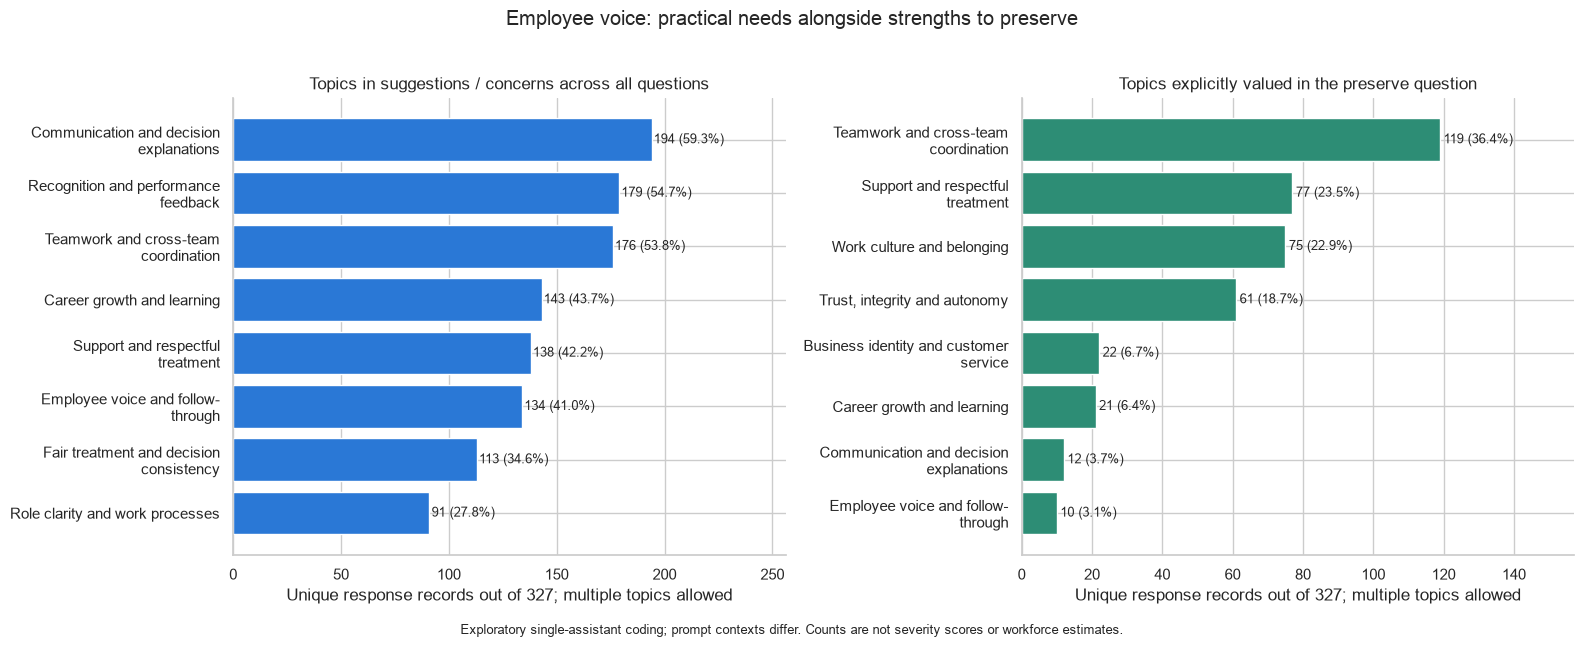

In [56]:
request_comments = coded_comments.loc[coded_comments["stance"].isin(["suggestion_or_concern", "mixed"])]
strength_comments = coded_comments.loc[
    coded_comments["question"].eq("oe_value_most") & coded_comments["stance"].eq("current_strength")]

def people_by_topic(frame):
    expanded = frame.explode("topics").dropna(subset=["topics"])
    return expanded.groupby("topics")["source_row"].nunique().reindex(TOPIC_DEFINITIONS, fill_value=0)

request_counts = people_by_topic(request_comments)
strength_counts = people_by_topic(strength_comments)
commenter_base = coded_comments["source_row"].nunique()
topic_summary = topic_codebook[["topic"]].copy()
topic_summary["request_record_n"] = request_counts
topic_summary["request_pct_all_327"] = request_counts / len(df) * 100
topic_summary["request_pct_any_commenter"] = request_counts / commenter_base * 100
topic_summary["preserve_record_n"] = strength_counts
topic_summary["preserve_pct_all_327"] = strength_counts / len(df) * 100
topic_summary = topic_summary.sort_values("request_record_n", ascending=False)
assert topic_summary[["request_record_n", "preserve_record_n"]].le(len(df)).all().all()
display(topic_summary.round(2))
# Sensitivity to the specifically flagged interpretation/reference cases, not an accuracy test.
review_sensitivity=pd.DataFrame({"topic":topic_codebook["topic"],
    "request_record_n":request_counts,
    "without_flagged_comments_n":people_by_topic(request_comments.loc[~request_comments["needs_review"]])})
review_sensitivity["change_n"]=review_sensitivity["without_flagged_comments_n"]-review_sensitivity["request_record_n"]
display(review_sensitivity.loc[review_sensitivity["change_n"].ne(0)].sort_values("request_record_n",ascending=False))

# Per-question topic counts use the same request/strength stance filter.
included_comments = pd.concat([request_comments.loc[request_comments["question"].ne("oe_value_most")], strength_comments]).drop_duplicates(["source_row","question"])
expanded_comments = included_comments.explode("topics", ignore_index=True).dropna(subset=["topics"])
question_topic_counts = pd.crosstab(
    expanded_comments["question"], expanded_comments["topics"]
).reindex(index=OE, columns=TOPIC_DEFINITIONS, fill_value=0).fillna(0).astype(int)
question_topic_pct = question_topic_counts.div(txt.notna().sum(), axis=0) * 100

# All exact duplicates remain in the main counts. Distinct texts are a different unit,
# used only to show whether topics rest on repeated wording; not an alternative prevalence estimate.
text_topic_rows = []
for row in request_comments.itertuples():
    normalised = " ".join(unicodedata.normalize("NFKC", str(txt.loc[row.source_row-1,row.question])).casefold().split())
    for topic in row.topics:
        text_topic_rows.append((topic,row.question,normalised))
wording_diversity = pd.DataFrame(text_topic_rows, columns=["topic_code","question","normalised"])
wording_diversity = wording_diversity.groupby("topic_code").agg(
    request_comment_occurrences=("normalised","size"),
    distinct_wordings=("normalised","nunique"))
display(wording_diversity.join(topic_codebook["topic"]).sort_values("request_comment_occurrences",ascending=False).head(8))

fig, axes = plt.subplots(1,2,figsize=(16,6))
for ax, col, title, color in [
    (axes[0],"request_record_n","Topics in suggestions / concerns across all questions",BLUE),
    (axes[1],"preserve_record_n","Topics explicitly valued in the preserve question","#2d8d75"),
]:
    ranked = topic_summary.sort_values(col,ascending=False).head(8).iloc[::-1]
    ax.barh([fill(t,31) for t in ranked["topic"]],ranked[col],color=color)
    for y,v in enumerate(ranked[col]):
        ax.text(v+1,y,f"{v} ({v/len(df)*100:.1f}%)",va="center",fontsize=9)
    ax.set(title=title,xlabel=f"Unique response records out of {len(df)}; multiple topics allowed",
           xlim=(0,ranked[col].max()*1.32))
fig.suptitle("Employee voice: practical needs alongside strengths to preserve", y=1.02)
fig.text(0.5,-0.02,"Exploratory single-assistant coding; prompt contexts differ. Counts are not severity scores or workforce estimates.",ha="center",fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "employee_voice_topics.png",dpi=180,bbox_inches="tight")

,comment_n,pct_of_308_nonblank
reply_type,,
suggestion_or_concern,180,58.44
no_concern_reported,73,23.70
item_nonresponse,28,9.09
unclear,20,6.49
mixed,5,1.62
current_strength,2,0.65


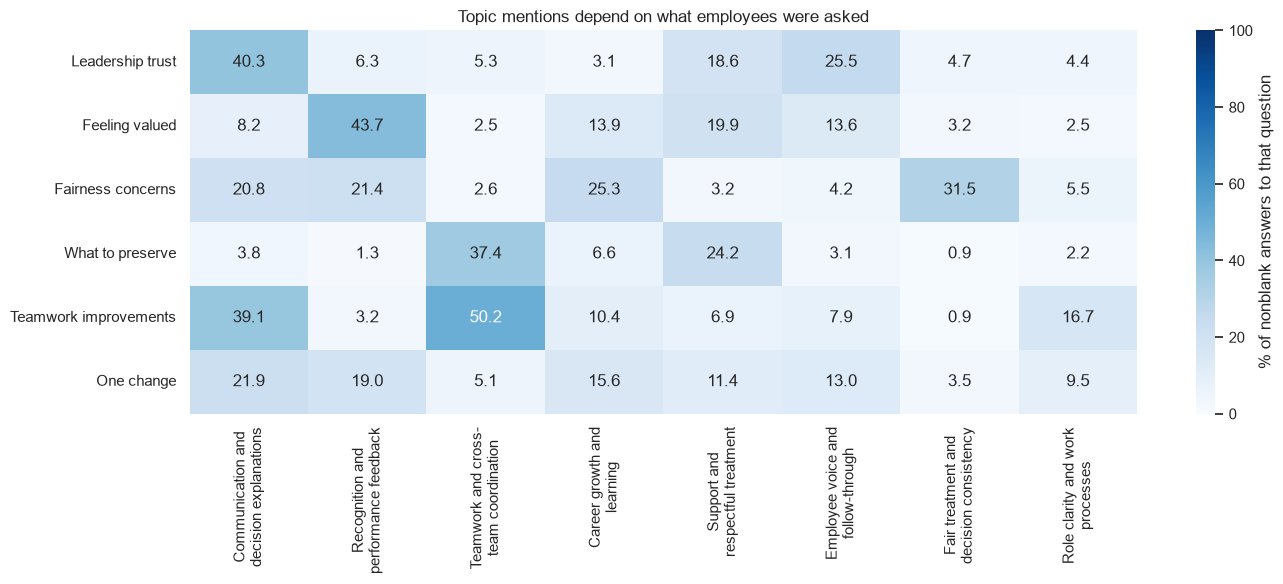

In [57]:
fairness_status = coded_comments.loc[coded_comments["question"].eq("oe_fairness_concern"),"stance"].value_counts()
fairness_status = fairness_status.rename_axis("reply_type").to_frame("comment_n")
fairness_status["pct_of_308_nonblank"] = fairness_status["comment_n"] / txt["oe_fairness_concern"].notna().sum() * 100
display(fairness_status.round(2))

fig,ax=plt.subplots(figsize=(14,6))
display_topics=list(request_counts.sort_values(ascending=False).head(8).index)
heat=question_topic_pct[display_topics].rename(index=q_labels,
    columns=topic_codebook["topic"].to_dict())
heat.columns=[fill(c,21) for c in heat.columns]
sns.heatmap(heat,annot=True,fmt=".1f",cmap="Blues",vmin=0,vmax=100,
            cbar_kws={"label":"% of nonblank answers to that question"},ax=ax)
ax.set(title="Topic mentions depend on what employees were asked",xlabel="",ylabel="")
fig.tight_layout()
fig.savefig(FIGURES / "comment_topics_by_question.png",dpi=180,bbox_inches="tight")

## 3.3 Bigrams and trigrams: phrase discovery, not another theme classifier

We use exact adjacent two- and three-word sequences, preserve negation, and never create phrases by deleting internal stopwords. Windows do not cross sentences, comments or questions. Hyphens are treated as word separators. Count each phrase **once per source record within a question**, so a long/repeated answer cannot dominate through word repetition. Keep phrases supported by at least five records; this is a readability rule, not statistical significance.

Names/titles and numerical identifiers are filtered before exporting phrases; only aggregate frequent phrases are exported. Filtering of boilerplate edge words and exact phrases repeated from the question happens after forming the original adjacent sequences. The English-focused extraction will miss transliterated and non-English variants, spelling differences and paraphrases; those were considered in contextual coding instead. A repeated phrase neither proves independent experiences nor copied/automated authorship. [NLTK collocation documentation](https://www.nltk.org/howto/collocations.html).

In [58]:
# No additional NLP packages, downloaded corpora or external processing are required.
name_tokens=set()
for name in raw["full_name"].dropna():
    name_tokens.update(w.casefold() for w in re.findall(r"[^\W\d_]+",str(name)) if len(w)>2)
blocked_tokens=name_tokens | {"mr","mrs","ms","sir","capt","captain","madam"}
edge_stop=set("a an the and or of to in on at for with from by is are be being been i me my we us our they them their it its this that would could should can do more most all one thing something when where whether whenever how what which who across between among about especially".split())
generic=set("employee employees organization organisation company thing things feel feeling feels make makes help helps would could should can one concern concerns biggest ensuring ensure supported respected valued provide providing each other better".split())
prompt_ngrams={}
for question in OE:
    prompt_tokens=re.findall(r"[^\W\d_]+",str(question_lookup[question]).casefold())
    prompt_ngrams[question]={" ".join(prompt_tokens[j:j+width])
        for width in [2,3] for j in range(len(prompt_tokens)-width+1)}
ngram_sets=defaultdict(set)
for row in included_comments.itertuples():
    text=unicodedata.normalize("NFKC",str(txt.loc[row.source_row-1,row.question])).casefold()
    # Preserve true token adjacency; use punctuation to stop a window across sentences.
    for sentence in re.split(r"[.!?;\n]+",text):
        tokens=re.findall(r"[^\W\d_]+(?:['’][^\W\d_]+)?",sentence,flags=re.UNICODE)
        for width in [2,3]:
            for start in range(len(tokens)-width+1):
                phrase_tokens=tokens[start:start+width]
                if " ".join(phrase_tokens) in prompt_ngrams[row.question]:
                    continue
                if phrase_tokens[0] in edge_stop or phrase_tokens[-1] in edge_stop:
                    continue
                if any(t in blocked_tokens for t in phrase_tokens):
                    continue
                if sum(t not in edge_stop|generic for t in phrase_tokens)<2:
                    continue
                ngram_sets[(row.question,width," ".join(phrase_tokens))].add(row.source_row)
ngram_rows=[(q,width,phrase,len(people),len(people)/txt[q].notna().sum()*100)
    for (q,width,phrase),people in ngram_sets.items() if len(people)>=5]
ngrams=pd.DataFrame(ngram_rows,columns=["question","words","phrase","record_n","pct_question_nonblank"])
ngrams=ngrams.sort_values(["question","words","record_n","phrase"],ascending=[True,True,False,True])
ngram_reference=ngrams.groupby(["question","words"],sort=False).head(6)
assert not ngrams["phrase"].map(lambda s:bool(set(s.split())&blocked_tokens)).any()
display(ngram_reference.assign(question=lambda t:t["question"].map(q_labels)).round(2))

,question,words,phrase,record_n,pct_question_nonblank
32,Fairness concerns,2,career growth,13,4.22
31,Fairness concerns,2,equal opportunities,11,3.57
39,Fairness concerns,2,growth opportunities,11,3.57
35,Fairness concerns,2,opportunities recognition,10,3.25
43,Fairness concerns,2,consistent criteria,8,2.60
...,...,...,...,...,...
100,What to preserve,3,want to lose,12,3.77
115,What to preserve,3,supportive work culture,9,2.83
93,What to preserve,3,supportive work environment,9,2.83
105,What to preserve,3,value the supportive,8,2.52


# Step 4 — Integrate the evidence and keep the useful distinctions

## 4.1 The same people: team support versus cross-team collaboration

The paired table compares two specific items from the same response records. This avoids treating every positive team rating as evidence that all collaboration works equally well. It remains descriptive: the wording differs and no causal effect is established.

In [59]:
paired_team=pd.crosstab(
    df["CAM1"].ge(4).map({True:"Within-team support favourable",False:"Within-team support 1–3"}),
    df["CAM2"].ge(4).map({True:"Cross-team collaboration favourable",False:"Cross-team collaboration 1–3"}))
display(paired_team)
within_fav_cross_not=int((df["CAM1"].ge(4)&df["CAM2"].le(3)).sum())

# This is a descriptive bridge, not a model or an independent effect estimate.
topic_item_map={"r":"RES4","v":"CRE5","d":"OVR2","f":"FAI3","t":"CAM2","m":"RES5","w":"FAI4"}
request_people={t:set(request_comments.loc[request_comments["topics"].map(lambda z:t in z),"source_row"])
                for t in TOPIC_DEFINITIONS}
bridge_rows=[]
for topic,item in topic_item_map.items():
    people=sorted(request_people[topic]); indices=[r-1 for r in people]
    favourable=int(df.loc[indices,item].ge(4).sum())
    bridge_rows.append((topic,topic_codebook.loc[topic,"topic"],item,len(people),favourable,
                        favourable/len(people)*100 if people else np.nan,
                        df[item].ge(4).mean()*100))
rating_comment_bridge=pd.DataFrame(bridge_rows,columns=["topic_code","topic","related_item",
    "request_record_n","requesters_favourable_n","requesters_favourable_pct","all_records_favourable_pct"])
display(rating_comment_bridge.round(2))

CAM2,Cross-team collaboration 1–3,Cross-team collaboration favourable
CAM1,,
Within-team support 1–3,13,16
Within-team support favourable,45,253


,topic_code,topic,related_item,request_record_n,requesters_favourable_n,requesters_favourable_pct,all_records_favourable_pct
0,r,Recognition and performance feedback,RES4,179,126,70.39,72.48
1,v,Employee voice and follow-through,CRE5,134,100,74.63,79.82
2,d,Career growth and learning,OVR2,143,129,90.21,90.52
3,f,Fair treatment and decision consistency,FAI3,113,75,66.37,74.62
4,t,Teamwork and cross-team coordination,CAM2,176,148,84.09,82.26
5,m,Support and respectful treatment,RES5,138,115,83.33,87.16
6,w,"Workload, boundaries and flexibility",FAI4,78,59,75.64,83.18


**Interpretation:** a favourable answer and a request for improvement can come from the same person. They need not contradict each other: the rating describes frequency on one item, while the prompt asks for something to improve. Broad comment categories and individual items are imperfect matches. The bridge does not identify hidden dissatisfaction, validate the coding, or show that the topic causes satisfaction or retention. It helps leaders ask a more precise follow-up question.

In [60]:
# Follow up the already-examined tenure pattern; no new search across every demographic cut.
tenure_order=["0 - 3","3 - 5","5 - 10","10 - 15","15 & Above"]
tenure_profile=df.groupby("tenure",observed=True).agg(
    response_n=("PRI3","size"), culture_mean=("CULTURE_MEAN","mean"),
    growth_mean=("OVR2","mean"), intention_to_stay_mean=("PRI3","mean"),
    recognition_favourable_pct=("RES4",lambda s:s.ge(4).mean()*100),
    growth_favourable_pct=("OVR2",lambda s:s.ge(4).mean()*100))
tenure_profile=tenure_profile.reindex(tenure_order)
tenure_profile["culture_mean_without_straightliners"]=df.loc[~df["straightliner"]].groupby(
    "tenure",observed=True)["CULTURE_MEAN"].mean()
for topic in ["r","d","v"]:
    mask=pd.Series([i+1 in request_people[topic] for i in df.index],index=df.index)
    counts=mask.groupby(df["tenure"],observed=True).sum().reindex(tenure_order)
    # Suppress sparse topic counts/rates; do not print source rows or quotes by group.
    tenure_profile[f"{topic}_request_n"]=counts.where(counts>=5)
    tenure_profile[f"{topic}_request_pct"]=counts.div(tenure_profile["response_n"]).mul(100).where(counts>=5)
tenure_profile.loc[tenure_profile["response_n"]<MIN_GROUP_N,tenure_profile.columns!="response_n"]=np.nan
display(tenure_profile.round(2))

,response_n,culture_mean,growth_mean,intention_to_stay_mean,recognition_favourable_pct,growth_favourable_pct,culture_mean_without_straightliners,r_request_n,r_request_pct,d_request_n,d_request_pct,v_request_n,v_request_pct
tenure,,,,,,,,,,,,,
0 - 3,124,4.30,4.40,4.41,73.39,87.90,4.19,72.0,58.06,67.0,54.03,52.0,41.94
3 - 5,53,4.21,4.30,4.25,66.04,84.91,4.11,34.0,64.15,24.0,45.28,25.0,47.17
5 - 10,56,4.38,4.59,4.61,73.21,94.64,4.30,25.0,44.64,21.0,37.50,23.0,41.07
10 - 15,41,4.70,4.83,4.90,85.37,97.56,4.60,24.0,58.54,11.0,26.83,14.0,34.15
15 & Above,53,4.32,4.49,4.51,66.04,92.45,4.20,24.0,45.28,20.0,37.74,20.0,37.74


## 4.2 Prioritise through evidence and seriousness, not a synthetic score

Reach, seriousness, cross-source support, feasibility and stakeholder context are separate considerations. We do not multiply arbitrary weights, classify individuals as disengaged, or assume the most mentioned topic is the most urgent.

Specific comments include requests/reports about workplace hygiene or equipment, public/harsh correction and contact outside working hours or during leave. These are **unverified employee accounts**, not established incidents or findings of misconduct. They merit confidential fact-finding even if their counts are lower than communication requests. The summaries below remove names, location details and distinctive narratives; they are paraphrases, not verbatim quotations.

The proposed actions below are options for organisation review. Owners are proposed roles, not commitments. Baselines come from this survey; targets should be agreed after verification. Improvements cannot be attributed to an intervention from a future before/after survey alone without considering other changes and response composition.

In [61]:
fav=lambda item:float(df[item].ge(4).mean()*100)
req=lambda topic:int(request_counts[topic])
preserve=lambda topic:int(strength_counts[topic])
hr_comm_n=int(df["hr_theme"].eq("Communication").sum())
fair_no_concern_n=int((coded_comments["question"].eq("oe_fairness_concern")&coded_comments["stance"].eq("no_concern_reported")).sum())

evidence_register=pd.DataFrame([
    ("E1","Preserve pride and everyday mutual support",
     f"Pride PRI1 {fav('PRI1'):.1f}% favourable; contribution PRI2 {fav('PRI2'):.1f}% (n={len(df)} each)",
     f"{preserve('t')} records explicitly value teamwork; {preserve('m')} value support or respectful treatment in the preserve prompt",
     "Protect helpful colleagues, approachable support and shared purpose while changing processes",
     "Business leaders and people managers","Track the same strength items and preserve-prompt themes alongside improvement work",
     "Do not infer that everyone experiences the same culture"),
    ("E2","Make recognition more consistent and specific",
     f"RES4 recognition {fav('RES4'):.1f}% favourable; {int(df.RES4.le(2).sum())} select 1–2, {int(df.RES4.eq(3).sum())} select Sometimes",
     f"{req('r')} unique records request recognition or performance feedback",
     "Review criteria, manager feedback habits and access to recognition across roles/branches",
     "HR and people managers","Baseline RES4; review recognition coverage and subsequent employee perceptions",
     "Recognition/feedback topic is broader than awards; no event-only solution assumed"),
    ("E3","Explain and consistently apply people decisions",
     f"FAI3 consistency {fav('FAI3'):.1f}% favourable; FAI5 decision understanding {fav('FAI5'):.1f}%",
     f"{req('f')} request fairer/consistent treatment; {fair_no_concern_n} fairness replies explicitly report no concern",
     "Clarify promotion, appraisal, opportunity and reward criteria; test whether employees understand them",
     "HR and business leadership","Baseline FAI3/FAI5; document criteria and track understanding/fairness in a comparable pulse",
     "Mixed experiences; coded requests are not proven unfair decisions"),
    ("E4","Improve cross-team execution without losing peer support",
     f"CAM1 within-team support {fav('CAM1'):.1f}% favourable vs CAM2 cross-team collaboration {fav('CAM2'):.1f}%; {within_fav_cross_not} rate CAM1 favourable but CAM2 1–3",
     f"{req('t')} request coordination/teamwork changes; role-clarity and handover examples provide context",
     "Pilot explicit handover ownership, backup contacts and escalation/response expectations",
     "Functional heads and operations managers","Baseline CAM2; pilot handover response/rework measures and ask whether cross-team support improved",
     "Specific process measures require a new operational baseline; social events alone may not address the issue"),
    ("E5","Make learning and progression visible, including mid-tenure follow-up",
     f"OVR2 growth {fav('OVR2'):.1f}% favourable overall; 3–5-year group growth mean {tenure_profile.loc['3 - 5','growth_mean']:.2f}/5, n={int(tenure_profile.loc['3 - 5','response_n'])}",
     f"{req('d')} request career growth/learning across the prompts",
     "Hold career conversations, clarify progression and pilot role-relevant/cross-functional learning",
     "HR/L&D and line managers","Baseline OVR2 by tenure; track access/completion and perceived usefulness/growth",
     "Intention to stay is not observed turnover; tenure patterns are exploratory and may reflect composition"),
    ("E6","Close the listening-to-action loop",
     f"CRE5 leadership acting on feedback {fav('CRE5'):.1f}% favourable; HR Communication chosen by {hr_comm_n}/{len(df)} records",
     f"{req('v')} request voice/follow-through; {req('c')} request communication/explanations (overlap allowed)",
     "Publish a concise issues/actions update with an owner, response expectation and progress review",
     "HR and leadership","Baseline CRE5; track acknowledgement, resolution and employee awareness of action",
     "More messaging alone does not demonstrate listening; no causal link to engagement established"),
    ("E7","Verify specific work-condition and treatment concerns promptly",
     "High overall ratings do not establish that specific facilities, boundary or respectful-treatment concerns are resolved",
     f"Broad request topics: facilities/tools/staffing {req('s')}, workload/boundaries {req('w')}, supervision/support {req('m')}; these counts are not counts of serious incidents",
     "Confidentially verify facilities/equipment and respectful-feedback/boundary accounts; resolve verified issues through existing processes",
     "Administration/IT, HR and relevant business managers","Verify conditions, establish an issue log and completion/follow-up measures; no invented incident baseline",
     "Unverified accounts; protect confidentiality, avoid named allegations and do not infer frequency from selected examples"),
],columns=["evidence_id","working_interpretation","rating_or_other_baseline","coded_comment_evidence",
           "proposed_action_for_review","proposed_owner","success_measure_and_baseline","limit"])
display(evidence_register)

,evidence_id,working_interpretation,rating_or_other_baseline,coded_comment_evidence,proposed_action_for_review,proposed_owner,success_measure_and_baseline,limit
0,E1,Preserve pride and everyday mutual support,Pride PRI1 92.4% favourable; contribution PRI2 95.7% (n=327 each),119 records explicitly value teamwork; 77 value support or respectful treatm...,"Protect helpful colleagues, approachable support and shared purpose while ch...",Business leaders and people managers,Track the same strength items and preserve-prompt themes alongside improveme...,Do not infer that everyone experiences the same culture
1,E2,Make recognition more consistent and specific,"RES4 recognition 72.5% favourable; 34 select 1–2, 56 select Sometimes",179 unique records request recognition or performance feedback,"Review criteria, manager feedback habits and access to recognition across ro...",HR and people managers,Baseline RES4; review recognition coverage and subsequent employee perceptions,Recognition/feedback topic is broader than awards; no event-only solution as...
2,E3,Explain and consistently apply people decisions,FAI3 consistency 74.6% favourable; FAI5 decision understanding 75.5%,113 request fairer/consistent treatment; 73 fairness replies explicitly repo...,"Clarify promotion, appraisal, opportunity and reward criteria; test whether ...",HR and business leadership,Baseline FAI3/FAI5; document criteria and track understanding/fairness in a ...,Mixed experiences; coded requests are not proven unfair decisions
3,E4,Improve cross-team execution without losing peer support,CAM1 within-team support 91.1% favourable vs CAM2 cross-team collaboration 8...,176 request coordination/teamwork changes; role-clarity and handover example...,"Pilot explicit handover ownership, backup contacts and escalation/response e...",Functional heads and operations managers,Baseline CAM2; pilot handover response/rework measures and ask whether cross...,Specific process measures require a new operational baseline; social events ...
4,E5,"Make learning and progression visible, including mid-tenure follow-up","OVR2 growth 90.5% favourable overall; 3–5-year group growth mean 4.30/5, n=53",143 request career growth/learning across the prompts,"Hold career conversations, clarify progression and pilot role-relevant/cross...",HR/L&D and line managers,Baseline OVR2 by tenure; track access/completion and perceived usefulness/gr...,Intention to stay is not observed turnover; tenure patterns are exploratory ...
5,E6,Close the listening-to-action loop,CRE5 leadership acting on feedback 79.8% favourable; HR Communication chosen...,134 request voice/follow-through; 194 request communication/explanations (ov...,"Publish a concise issues/actions update with an owner, response expectation ...",HR and leadership,"Baseline CRE5; track acknowledgement, resolution and employee awareness of a...",More messaging alone does not demonstrate listening; no causal link to engag...
6,E7,Verify specific work-condition and treatment concerns promptly,"High overall ratings do not establish that specific facilities, boundary or ...","Broad request topics: facilities/tools/staffing 39, workload/boundaries 78, ...",Confidentially verify facilities/equipment and respectful-feedback/boundary ...,"Administration/IT, HR and relevant business managers","Verify conditions, establish an issue log and completion/follow-up measures;...","Unverified accounts; protect confidentiality, avoid named allegations and do..."


In [62]:
display(Markdown(f"""
## 4.3 Working organisational story — evidence to test with leaders

**Preserve the foundation.** Respondents describe pride and helpful working relationships: PRI1 is {fav('PRI1'):.1f}% favourable, and {preserve('t')} source records explicitly value teamwork in the preserve question. These are assets to protect, not reasons to dismiss concerns.

**Make everyday practices more consistent.** Recognition RES4 is {fav('RES4'):.1f}% favourable; {req('r')} records request recognition/feedback, and {req('f')} request fairer or more consistent treatment. The interpretation is an opportunity to examine criteria, explanations and manager practices—not proof that all decisions are unfair. {fair_no_concern_n} fairness replies report no current concern.

**Distinguish a helpful team from smooth cross-team execution.** {within_fav_cross_not} records rate support within their own team favourably but cross-team collaboration at 1–3. The comments make handovers, ownership and coordination practical follow-up topics; a team outing is not assumed to fix these processes.

**Turn listening into visible follow-through.** {req('v')} records request employee voice/action on feedback. Combine a response process with clear progress communication and check whether employees actually notice improvement. [CIPD employee voice guidance](https://www.cipd.org/uk/knowledge/factsheets/voice-factsheet).

**Do not rank away specific concerns.** Targeted requests/reports about working conditions, respectful feedback and time boundaries warrant confidential verification alongside the broader priorities.

These are exploratory interpretations of this response pool and one assistant coding pass. Topic mentions are prompted, multi-label and not independently validated. Final priorities and targets need organisational context and team review; neither a fuzzy score nor a more complex model removes those limits.
"""))


## 4.3 Working organisational story — evidence to test with leaders

**Preserve the foundation.** Respondents describe pride and helpful working relationships: PRI1 is 92.4% favourable, and 119 source records explicitly value teamwork in the preserve question. These are assets to protect, not reasons to dismiss concerns.

**Make everyday practices more consistent.** Recognition RES4 is 72.5% favourable; 179 records request recognition/feedback, and 113 request fairer or more consistent treatment. The interpretation is an opportunity to examine criteria, explanations and manager practices—not proof that all decisions are unfair. 73 fairness replies report no current concern.

**Distinguish a helpful team from smooth cross-team execution.** 45 records rate support within their own team favourably but cross-team collaboration at 1–3. The comments make handovers, ownership and coordination practical follow-up topics; a team outing is not assumed to fix these processes.

**Turn listening into visible follow-through.** 134 records request employee voice/action on feedback. Combine a response process with clear progress communication and check whether employees actually notice improvement. [CIPD employee voice guidance](https://www.cipd.org/uk/knowledge/factsheets/voice-factsheet).

**Do not rank away specific concerns.** Targeted requests/reports about working conditions, respectful feedback and time boundaries warrant confidential verification alongside the broader priorities.

These are exploratory interpretations of this response pool and one assistant coding pass. Topic mentions are prompted, multi-label and not independently validated. Final priorities and targets need organisational context and team review; neither a fuzzy score nor a more complex model removes those limits.


In [63]:
# Export aggregate presentation material only. Coding ledger and raw comments stay local/in-notebook.
review_sensitivity.to_csv(TABLES / "coding_interpretation_sensitivity.csv")
topic_codebook.to_csv(TABLES / "qualitative_topic_codebook.csv")
topic_summary.to_csv(TABLES / "employee_voice_topic_summary.csv")
coding_coverage.to_csv(TABLES / "qualitative_coding_coverage.csv")
question_topic_counts.rename(columns=topic_codebook["topic"].to_dict()).to_csv(TABLES / "comment_topics_by_question.csv")
ngram_reference.to_csv(TABLES / "recurring_phrases.csv",index=False)
rating_comment_bridge.to_csv(TABLES / "rating_comment_bridge.csv",index=False)
paired_team.to_csv(TABLES / "paired_team_support_comparison.csv")
tenure_profile.to_csv(TABLES / "tenure_followup_profile.csv")
evidence_register.to_csv(TABLES / "organisational_evidence_and_action_options.csv",index=False)
assert len(coded_comments)==1892
assert len(coded_comments[["source_row","question"]].drop_duplicates())==1892
assert len(evidence_register)==7
assert all(t in TOPIC_DEFINITIONS for topics in coded_comments["topics"] for t in topics)
assert paired_team.to_numpy().sum()==len(df)
assert set(request_comments["stance"])<= {"suggestion_or_concern","mixed"}
display(Markdown("**Outputs:** three presentation figures and eleven aggregate reference tables are saved under `reports/`. The raw workbook is unchanged. Coding remains a single-assistant exploratory interpretation requiring team review before final presentation; no PowerPoint has been generated at this stage."))

**Outputs:** three presentation figures and eleven aggregate reference tables are saved under `reports/`. The raw workbook is unchanged. Coding remains a single-assistant exploratory interpretation requiring team review before final presentation; no PowerPoint has been generated at this stage.

---
# Annexure

## A. Essential terms and interpretation

| Term | Meaning and use in this project |
|---|---|
| CRE / RES / FAI / PRI / CAM / OVR | Credibility / Respect / Fairness / Pride / Camaraderie / Overall Employee Experience; supplied question blocks |
| OE / HR | Open-ended response / Human Resources |
| AM / TL / R&R | Assistant Manager / Team Leader / Rewards and Recognition |
| Culture summary | Our descriptive 25-item mean; not a validated or official culture summary |
| Favourable / unfavourable | Scores 4–5 / 1–2; show the valid-answer denominator and retain Sometimes separately |
| Percentage points | Subtract percentages directly; 80% to 85% is +5 percentage points |
| Reliability / validity | Consistency of a measure / evidence supporting an interpretation and intended use; one does not prove the other |
| Alpha | Internal consistency statistic under assumptions; not a universal pass/fail test or proof of one factor |
| Spearman rho | Rank association; no causal or independent-effect interpretation |
| p-value | Under the specified null model and assumptions, probability of a test statistic at least as extreme as observed; not the probability the null is true or that chance caused the result |
| BY-adjusted p-value | Adjustment controlling false discovery rate under general dependence, when the input tests are valid |
| Kruskal–Wallis | Independent-group rank comparison; does not identify which groups differ; median interpretation needs appropriate distributional assumptions |
| Cramér's V | Descriptive categorical association; sparse tables and sample size affect interpretation |
| Ceiling effect / straight-lining | Concentration at the top category / one category used throughout; do not automatically discard responses |
| eNPS | A recommendation measure using an NPS scoring protocol; not computable from our 1–5 OVR1 item as standard eNPS |

Definitions and methodological decisions are expanded in Step 1; linked research sources and the final methodology table provide references.

## B. Variables created in this notebook (`data/processed/survey_clean.csv`)

| Column | Type | Definition |
|---|---|---|
| `CRE1` … `OVR5` | int 1–5 | Likert answers converted to numbers (see C.1) |
| `CRE`, `RES`, `FAI`, `PRI`, `CAM`, `OVR` | float 1–5 | Dimension scores: mean of 5 items |
| `CULTURE_MEAN` | float 1–5 | Mean of 25 items (all dimensions except OVR) |
| `fav_pct` | float 0–100 | Respondent's % of the 30 answers that are 4 or 5 |
| `level` | category | Designation grouped into 7 levels (see C.2) |
| `region` | category | City grouped into 5 regions (see C.3) |
| `dept_group` | category | Department, with those under 10 respondents merged into *Other* |
| `hr_theme` | category | HR-priority option grouped into 8 themes (see C.4) |
| `straightliner` | bool | Same answer to all 30 items |
| `gave_name` | bool | Filled in the optional name field (the name itself is dropped) |

Actual names are excluded from `survey_clean.csv`. The codebook retains the optional field definition, never name values.

## C. Mappings used

**C.1 Likert scale**

| Raw label(s) | Score |
|---|---|
| Almost never · Almost Never | 1 |
| Rarely | 2 |
| Sometimes | 3 |
| Usually · Often (Hindi form) | 4 |
| Almost always · Almost Always · Always (Malayalam form) | 5 |

**C.2 Level** (keyword rules, checked in this order)

| Level | Designations containing |
|---|---|
| 6 Sr Leadership | chief, general manager, head of |
| 4 AM / TL | assistant manager, team leader, supervisor |
| 5 Manager+ | manager (Manager, Sr/Deputy/Branch/Area/Project Manager…) |
| 3 Sr Executive | senior executive |
| 2 Executive | executive |
| 1 Junior / Support | junior, assistant, runner, off role |
| 0 Unclear | anything else (e.g. *SALES*, *IMPORT*, *Branch Accountant*, *Do not want to disclose*) |

**C.3 Region**

| Region | Locations |
|---|---|
| West | Mumbai, Nhava Sheva, Pune, Ahmedabad, Gandhidham, Baroda, Mundra, Aurangabad |
| North | Noida, Kanpur, Ludhiana, Jaipur, Panipat |
| South | Cochin, Chennai, Hyderabad, Bangalore, Coimbatore, Vizag, Tuticorin |
| East | Kolkata |
| Overseas | Nairobi, New Jersey |

**C.4 HR theme** (from the workbook's `Sheet2`)

| Theme | HR-priority options |
|---|---|
| Communication | Listening to employees and their concerns · Keeping employees informed |
| Grievances | Help resolve employee problems · Supporting employees when they need help |
| Development | Help employees progress in their careers |
| Benefits & Facilities | Improve employee benefits and facilities |
| R&R | Recognising and appreciating good work |
| Process & Policies | Making rules and processes simple |
| Approachable | Being available and easy to approach |
| Engagement | Employee activities and engagement |

## D. Data lineage and reproducibility

| Item | Detail |
|---|---|
| Source | `data/raw/Your Voice- Responses 21 OCT - FINAL.xlsx`; keep unchanged |
| Analysis sheet | `SWL - MASTERDATA`: 327 responses, 43 source columns, two header rows |
| Source discrepancy | Language exports total 330; master has 327. A verified row-level reconciliation is not available |
| Transformations | Harmonise response labels, repair designation header, remove name, create documented reporting groups and working scores |
| Grouping limits | Job levels are keyword approximations; Other departments are heterogeneous; no weighting to workforce composition |
| Outputs | `survey_clean.csv` and `codebook.csv`; regenerate by running top to bottom |
| Schema change | `TRUST_INDEX` renamed `CULTURE_MEAN` to identify an analyst-created descriptive measure |
| Environment | Project `.venv`, dependencies pinned by `uv.lock`; all analysis remains in this notebook |

The option mappings above document transformations; the live codebook in §2 contains all source questions. Do not infer survey collection procedures or removal reasons from row counts alone.

# Methodology reference — maintained as the last Markdown cell

Status as of **29 October 2026**. “Used” means executed in this notebook; “planned” means specified but not performed. All results describe responding records unless stated otherwise. Research links support the method's meaning, not the validity of our particular survey.

| Method / measure | Organisational purpose | Inputs / assumptions | Decision and current status | Limits / reference |
|---|---|---|---|---|
| Source and quality audit | Establish a trustworthy base | Master sheet, headers, missingness, label mapping, row counts | **Used**; raw preserved; names removed; row-count discrepancy documented | Unique employee identity, sampling frame and removal log not verified |
| Item distributions and favourable % | Identify strengths and improvement opportunities | Valid n per item; categories 1–5; favourable=4–5, unfavourable=1–2 | **Used, primary descriptive evidence** | Sometimes is not neutral; no borrowed external thresholds. [Civil Service example](https://www.gov.uk/government/publications/civil-service-people-survey-2025-results/quality-and-methodology-information-for-the-civil-service-people-survey-2025) |
| Item/block means and culture summary | Provide a compact overview beside distributions | Equal category spacing, equal weights; culture summary uses 25 items | **Used as descriptive working measures**, not validated or branded indices | Do not correlate a composite with its own included outcome as driver evidence |
| Cronbach alpha and corrected item–total correlations | Inspect coherence of supplied blocks | Covariation of items; interpret alpha under its assumptions | **Used as diagnostics**; no automatic item deletion | Does not establish dimensionality or validity; EFA/CFA remains conditional |
| Spearman correlations | Explore relationships with advocacy, intention to stay and satisfaction | Independent respondent records; ordinal ranking; outcomes excluded from predictor list | **Used, exploratory**; no significance-based item screening | Associations do not establish causality or independent effects |
| Group descriptions and provisional n≥10 reporting rule | Understand variations relevant to follow-up | Tenure, department, region, gender, approximate levels | **Used**; show n; suppress small-group scores in comparison tables | Threshold is a project rule, not a proof of privacy or adequate precision |
| Kruskal–Wallis plus BY FDR adjustment | Assess exploratory differences across eligible groups | Independent records; adequate group sizes; 11 overlapping full/sensitivity tests | **Used**, joint family of 11 tests; retain effect size/context in interpretation | Omnibus result does not identify pairs or prove a median shift. [Kruskal](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.kruskal.html), [BY](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.false_discovery_control.html) |
| Response-style sensitivity | Check dependence on identical-category respondents | Keep full sample primary; compare a labelled alternative | **Used** for scores and exploratory tests | Exclusion is not assumed to improve validity |
| HR-priority counts and descriptive Cramér's V | Understand the one HR priority selected | Recompute from master; inspect expected cell counts and group sizes | **Used descriptively**; sparse-table asymptotic p-values withheld | V may be unstable; permutation inference conditional on decision need. [SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html) |
| Comment coverage and repeated-text flags | Establish usable qualitative material | Six questions, nonblank answers, context-review flags | **Used as profiling only** | Short or repeated answers are not automatically invalid |
| Codebook-based qualitative content analysis | Explain employee concerns, strengths and suggestions | Contextual reading, code definitions, pilot/revision, multi-label records, review trail | **Used, exploratory single-assistant semantic coding** of all 1,892 nonblank comments; explicit multi-label ledger and coverage audit; independent validation not performed | Avoid equating word counts or automatic sentiment with reviewed themes; distinct from reflexive TA. [Method distinctions](https://www.thematicanalysis.net/understanding-ta/), [review guidance](https://www.thematicanalysis.net/editor-checklist/) |
| Quantitative–qualitative integration | Build an evidence-backed organisational story | Rating patterns, reviewed coded comments, HR choices; show disagreements | **Used, exploratory**; paired item table, rating–comment bridge, question-context profiles and evidence register | Convergence is not causal proof; prompted topic counts are not independent validation |
| Equal-weight frequency evaluation equivalence check | Test whether a proposed fuzzy-style calculation adds information | Complete responses, empirical category shares, equal item weights, scores 1–5 | **Used as an algebra/data check**; exactly equals the ordinary mean, so omit as a separate insight | Specific construction, not a validation or rejection of all fuzzy approaches |
| Calibrated fuzzy analysis | Potentially represent graded decision concepts | Explicit memberships, anchors, weights, validation and sensitivity | **Conditional; not implemented**; no calibrated inputs supplied | Membership is not probability; adopt only with decision value beyond baseline. [Zadeh](https://doi.org/10.1016/S0019-9958(65)90241-X), [questionnaire model](https://arxiv.org/abs/1912.09883) |
| EFA/CFA or multivariable ordinal models | Resolve a necessary measurement or association question | Ordinal-aware specification, identifiability, fit, sample/ceiling checks and validation | **Conditional; not implemented** | No automatic EFA→CFA validation on the same sample; predictive validation is not causal identification |
| Prioritisation, action roadmap and evaluation | Translate evidence into measurable interventions | Reach, severity, evidence, feasibility, proposed owners, baseline and review measures | **Evidence register and action options drafted**; final targets, owner agreement and executive PowerPoint remain later | No invented ROI, causal effects or success targets. [CIPD](https://www.cipd.org/uk/knowledge/guides/analytics-practitioner-guide/) |
| Exact bigrams and trigrams | Navigate recurring phrases and check topic labels | Adjacent words, sentence/comment boundaries, preserved negation, unique-record support ≥5, name filtering | **Used as supporting evidence**, not thematic coding or sentiment analysis | English-focused; surface form and repeated wording affect counts. [NLTK](https://www.nltk.org/howto/collocations.html) |
| Semantic coding ledger and coverage | Make qualitative decisions reproducible and preserve no-concern/unclear answers | Hash-locked comment order; one assistant read/coding pass; multi-label topics and explicit stance | **Used**; all nonblank answers accounted for, cross-references/translation flags documented | No independent human validation or inter-rater reliability; counts exploratory. [Framework method](https://pmc.ncbi.nlm.nih.gov/articles/PMC3848812/) |
| Paired and contextual descriptive follow-up | Examine within/cross-team differences and tenure questions already raised | Same-record item counts, group n and suppression; no new demographic significance search | **Used**; counts/means/favourable shares and response-style sensitivity | Different item wording and group composition limit interpretation; not actual turnover prediction |

**Not selected:** standard eNPS from the five-point item; an official Trust Index label for our custom mean; automatic causal “driver” claims; uncalibrated fuzzy rankings; generic word clouds as qualitative findings; unchecked sparse-table inference; individual attrition predictions without observed outcomes. [NPS protocol](https://www.netpromotersystem.com/about/measuring-your-net-promoter-score/).